# <center>🧠 Лекция 5. От нейрона к нейронной сети: как машина учится</center>
## <center>从神经元到神经网络</center>

### <center>Прикладные технологии искусственного интеллекта</center>
#### <center>Модуль 3 — Введение в глубокое обучение · 2 академических часа (90 минут)</center>

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #2E7D32; margin: 20px 0;'>
<b>🎯 Цели лекции:</b><br>
1. объяснять соответствие «биологический нейрон ↔ искусственный нейрон» и роль весов, смещения, активации;<br>2. считать выход нейрона вручную по заданным весам;<br>3. объяснять, зачем нужны нелинейные активации и скрытые слои (пример XOR);<br>4. описывать обучение сети: потери, градиентный спуск, backprop, learning rate, эпохи;<br>5. распознавать переобучение по кривым и называть 4 способа борьбы с ним;<br>6. собирать минимальный обучающий цикл на PyTorch и знать место китайских фреймворков (PaddlePaddle, MindSpore).
</div>

<div style='background-color: #FFF3E0; padding: 12px; border-left: 5px solid #FB8C00; margin: 20px 0;'>
<b>⏱️ План работы (90 минут):</b><br>
• Биология → арифметика: искусственный нейрон <i>(15 мин)</i><br>• Активации: зачем нелинейность <i>(10 мин)</i><br>• Слои и глубина: XOR и «перепаковка» пространства <i>(15 мин)</i><br>• Как сеть учится: потери, градиент, backprop <i>(25 мин)</i><br>• Переобучение и регуляризация <i>(10 мин)</i><br>• PyTorch: пять блоков и цикл обучения <i>(10 мин)</i><br>• Мини-тест и итоги <i>(5 мин)</i>
</div>

<div style='background-color: #E3F2FD; padding: 12px; border-left: 5px solid #1976D2; margin: 20px 0;'>
<b>📦 Что понадобится:</b> PyTorch (или PaddlePaddle/MindSpore), matplotlib, numpy.
</div>

<div style='background-color: #FCE4EC; padding: 12px; border-left: 5px solid #C2185B; margin: 20px 0;'>
<b>💡 Как работать с ноутбуком.</b> Теория читается сверху вниз; все рисунки уже внедрены в файл — внешние контейнеры и сетка не нужны. Демонстрационные ячейки с кодом можно запускать по порядку.
</div>


In [ ]:
# Настройка ноутбука: графики внутри документа, кириллица и иероглифы
%matplotlib inline
import numpy as np
import matplotlib.font_manager as fm
import os
for fp in ['/usr/share/fonts/truetype/chinese/NotoSansSC-Regular.ttf']:
    if os.path.exists(fp):
        fm.fontManager.addfont(fp)
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('Настройка завершена. Запускайте ячейки по порядку — сверху вниз.')

Настройка завершена. Запускайте ячейки по порядку — сверху вниз.


## 1. От биологии к арифметике

В мозге около 86 миллиардов нейронов. Каждый принимает сигналы через **дендриты**, суммирует их в теле, и при превышении порога посылает импульс по **аксону** к следующим. Сила связей (синапсов) меняется с опытом — «нейроны, которые срабатывают вместе, связываются» (правило Хебба). Это и есть биологическая основа обучения.

В 1943 году Маккаллок и Питтс предложили дерзкий пересказ: а что если счесть это арифметикой?


## 1. Искусственный нейрон (神经元) (0–20 мин)

Искусственный нейрон — это упрощённая математическая модель биологического нейрона. Он делает всего две вещи:

1. **Считает взвешенную сумму:** Умножает каждый входной сигнал на его «важность» (вес) и складывает их, добавляя смещение (bias).
2. **Применяет функцию активации:** Решает, передать ли сигнал дальше.

### ⚡ Функция активации ReLU (Rectified Linear Unit)
Самая популярная функция. Её правило гениально просто:  
**«Отрицательное обнули, положительное оставь»** (负数变零，正数保留).
- Если сумма < 0 → выход = 0
- Если сумма ≥ 0 → выход = сумма

Из множества таких нейронов собираются **слои**: входной (получает данные), скрытые (ищут закономерности) и выходной (даёт ответ).

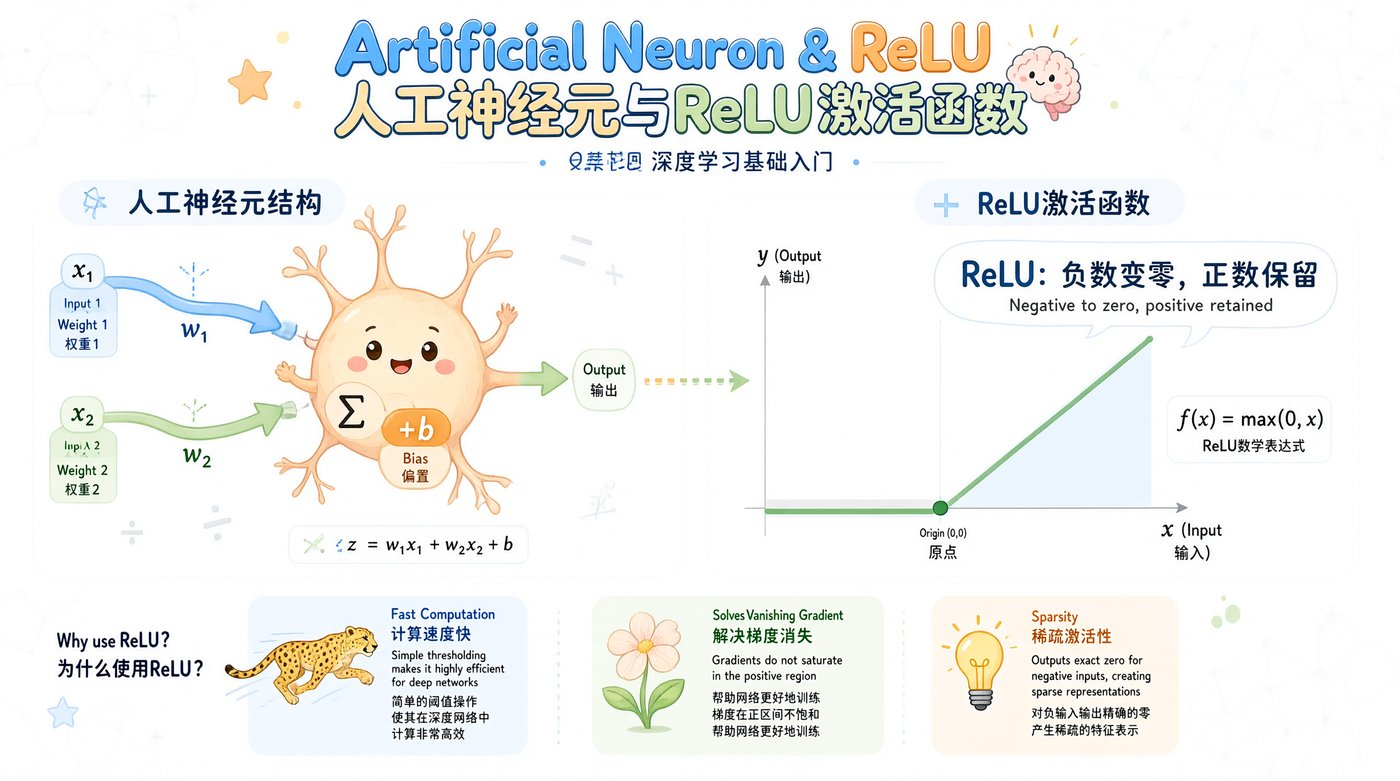
*Рис. 1. Искусственный нейрон: взвешенная сумма входов и функция активации ReLU.*

> 👨‍🏫 **Игровая демонстрация для аудитории:**  
> Предложите 3-м студентам сыграть роль нейронов. Студент А (вход) называет число. Студент Б (нейрон) умножает его на «вес» (например, 2), прибавляет «смещение» (-5) и применяет правило ReLU. Студент В (выход) записывает итог. Это наглядно показывает передачу данных по цепочке.
>
### Из чего состоит нейрон?
1. **Входы ($x_1, x_2, x_3$)**: числа, которые приходят в нейрон (признаки).
2. **Веса ($w_1, w_2, w_3$)**: важность каждого входа. Если вес большой, этот признак сильно влияет на результат.
3. **Сумматор (Σ)**: считает **взвешенную сумму (加权和)**: $z = w_1x_1 + w_2x_2 + w_3x_3$.
4. **Функция активации (激活函数, ReLU)**: решает, «активировать» ли нейрон.
   - **ReLU** (Rectified Linear Unit): «Отрицательное обнули, положительное оставь». Формула: $y = \max(0, z)$.
5. **Выход ($y$)**: результат, который передаётся следующему слою.

### Слои нейросети (神经网络的层)
Нейроны объединяются в слои:
- **Входной слой (输入层)**: получает сырые данные (пиксели, числа).
- **Скрытые слои (隐藏层)**: извлекают закономерности (чем их больше, тем «глубже» обучение).
- **Выходной слой (输出层)**: выдаёт финальный ответ (например, вероятность того, что на фото кошка).

> 🎮 **Игровая демонстрация для аудитории (5 мин):**
> Попросите 3 студентов быть «входами» (назовите числа, например, 2, 3, 1).
> Один студент — «сумматор» (умножает на веса, которые вы даёте, и складывает).
> Другой студент — «ReLU» (если число отрицательное, говорит «0», если положительное — повторяет его).
> Покажите, как данные проходят по цепочке!

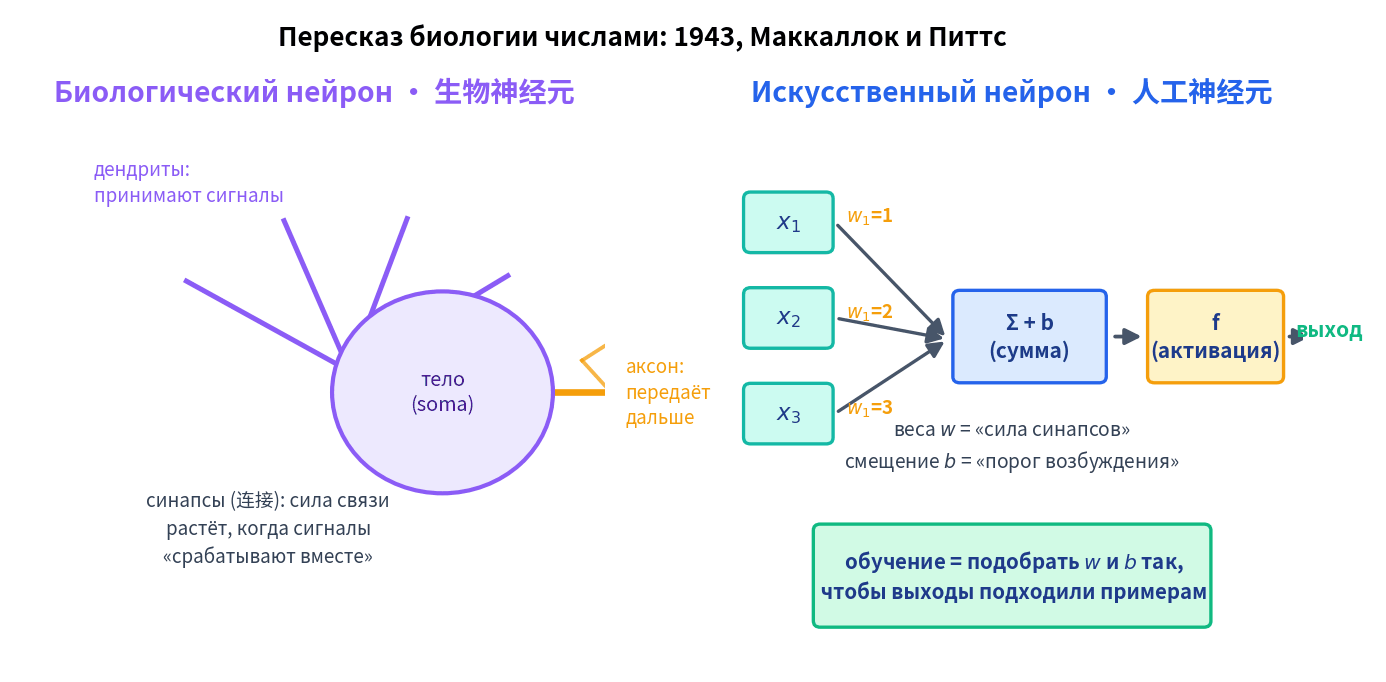

Искусственный нейрон — это буквально **взвешенная сумма + порог-нелинейность**:

$$\hat{y} = f(w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b)$$

- $x_i$ — входы (признаки, или выходы предыдущих нейронов);
- $w_i$ — **веса** (weights, 权重) — «сила синапсов»: чем больше вес, тем громче голос входа;
- $b$ — **смещение** (bias, 偏置) — порог возбуждения;
- $f$ — **функция активации** — решает, «выстрелит» ли нейрон.

Посчитаем руками, чтобы снять остатки мистики:


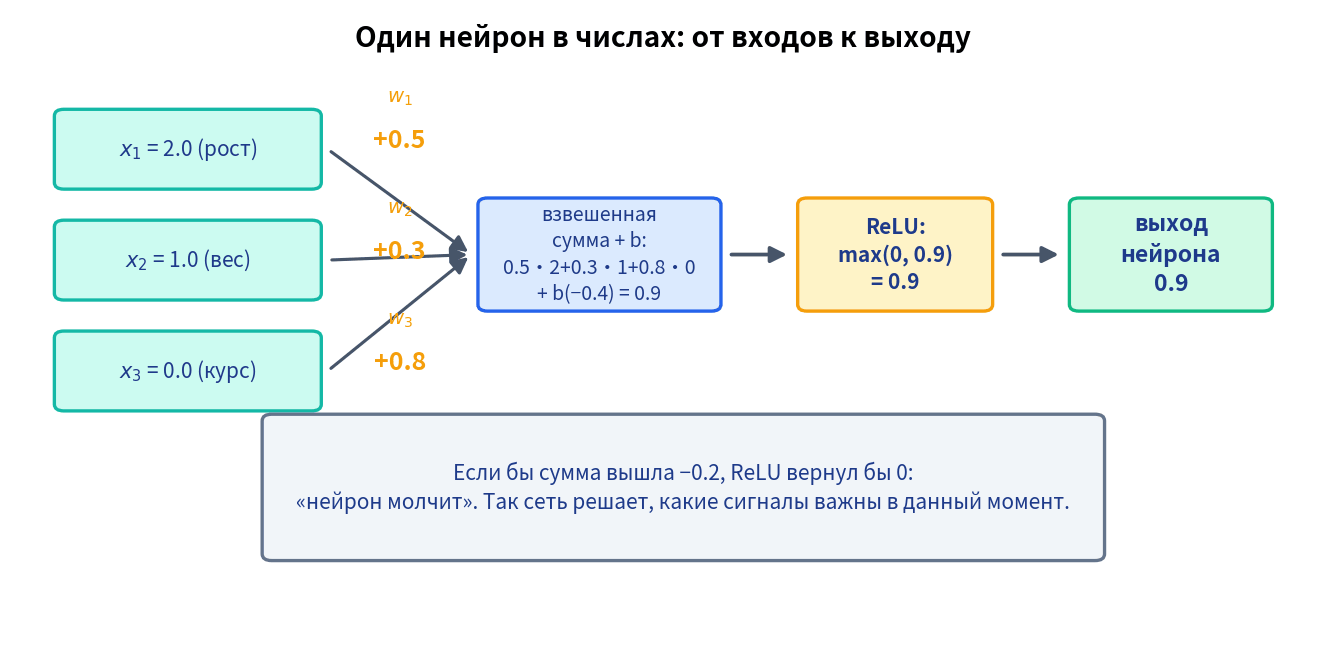


In [ ]:
# тот же нейрон — три строчки NumPy
import numpy as np

x = np.array([2.0, 1.0, 0.0])      # входы (рост, вес, курс)
w = np.array([0.5, 0.3, 0.8])      # веса
b = -0.4                           # смещение

z = (x * w).sum() + b              # взвешенная сумма: 0.9
y_hat = max(0.0, z)                # ReLU-активация
print(f"z = {z:.2f}, после ReLU: {y_hat:.2f}")
print("порог был бы ниже — нейрон молчал бы, выйдя в 0")

z = 0.90, после ReLU: 0.90
порог был бы ниже — нейрон молчал бы, выйдя в 0


In [ ]:
# Демонстрация работы одного нейрона с функцией активации ReLU
import numpy as np

def relu(x):
    """Функция активации ReLU: отрицательное обнули, положительное оставь"""
    return np.maximum(0, x)

# Входы (например, признаки: размер дома, количество комнат)
inputs = np.array([50.0, 2.0])

# Веса (важность каждого признака) и смещение (bias)
weights = np.array([0.1, 15.0])
bias = -10.0

# 1. Взвешенная сумма
weighted_sum = np.dot(inputs, weights) + bias
print(f"Взвешенная сумма: {weighted_sum}")

# 2. Применение функции активации
output = relu(weighted_sum)
print(f"Выход нейрона (после ReLU): {output}")

# Попробуем с другими входами, где сумма будет отрицательной
inputs_bad = np.array([10.0, 0.0])
weighted_sum_bad = np.dot(inputs_bad, weights) + bias
print(f"\nПлохие входы. Взвешенная сумма: {weighted_sum_bad}")
print(f"Выход нейрона (после ReLU): {relu(weighted_sum_bad)} (Обнулено!)" )

Взвешенная сумма: 25.0
Выход нейрона (после ReLU): 25.0

Плохие входы. Взвешенная сумма: -9.0
Выход нейрона (после ReLU): 0.0 (Обнулено!)


## 2. Активации: маленькая нелинейность, решающая всё

Без $f$ (или с $f(z)=z$) цепочка нейронов схлопывается в одну линейную формулу: сколько слоёв ни ставь, получится $y = kx + b$. Вся выразительность сетей — в **нелинейных активациях**:


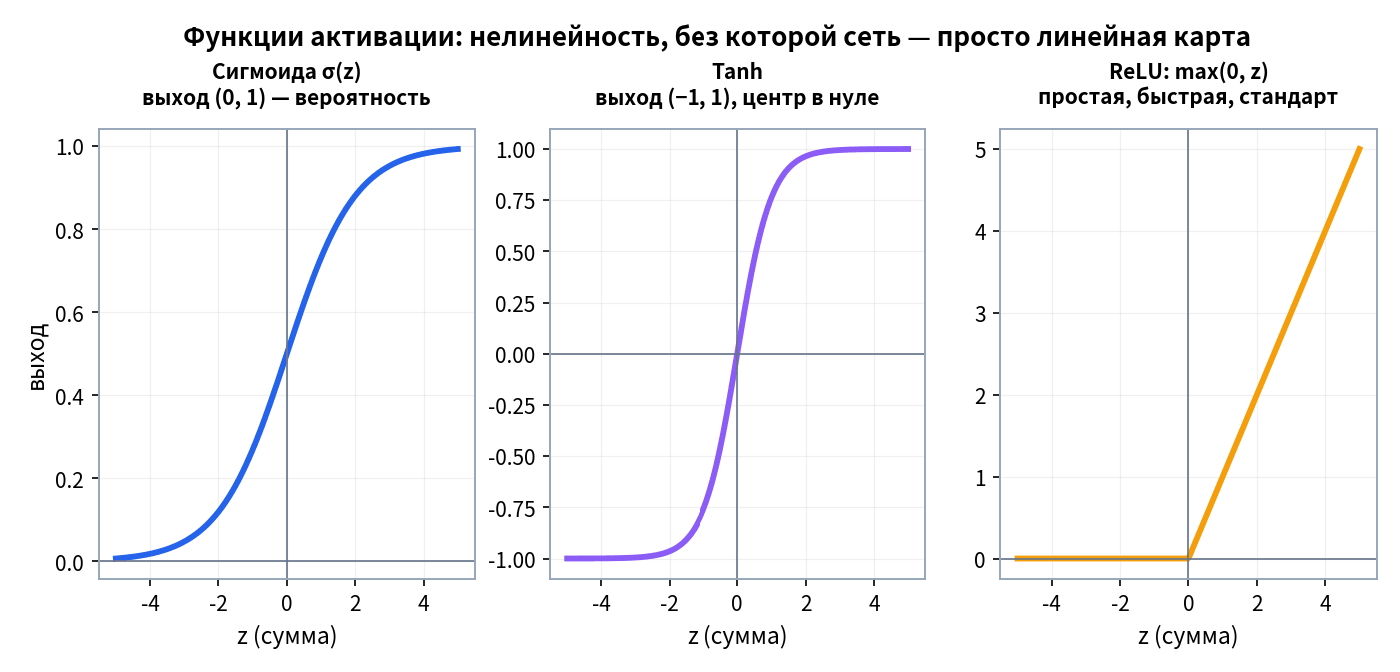

История трёх функций — история компромиссов:

- **Сигмоида** $\sigma(z) = \frac{1}{1+e^{-z}}$ — гладкая, даёт вероятность, идеальна в последнем слое бинарной классификации. Проблема: при $|z|>4$ производная почти нулевая — «исчезающий градиент», глубокие сети переставали учиться.
- **Tanh** — тот же колокол, но от −1 до 1 и с нулевым центром; учится чуть лучше сигмоиды.
- **ReLU** $=\max(0, z)$ — «включился/молчит». Производная равна 1 всюду справа от нуля: градиенты не исчезают, считать быстрее на порядок. С 2012 года — рабочий стандарт скрытых слоёв (внизу таблицы — её вариации GELU/LeakyReLU, которые встретим в трансформерах).

| Активация | Где ставить |
|---|---|
| ReLU | скрытые слои «по умолчанию» |
| сигмоида | выход бинарной классификации |
| softmax | выход многоклассовой классификации (лекция 6) |
| GELU | внутри трансформеров (лекция 7) |


## 3. Слои и глубина: зачем нейроны собирают в этажи

Один нейрон — одна линия. Сеть — этажи преобразований:


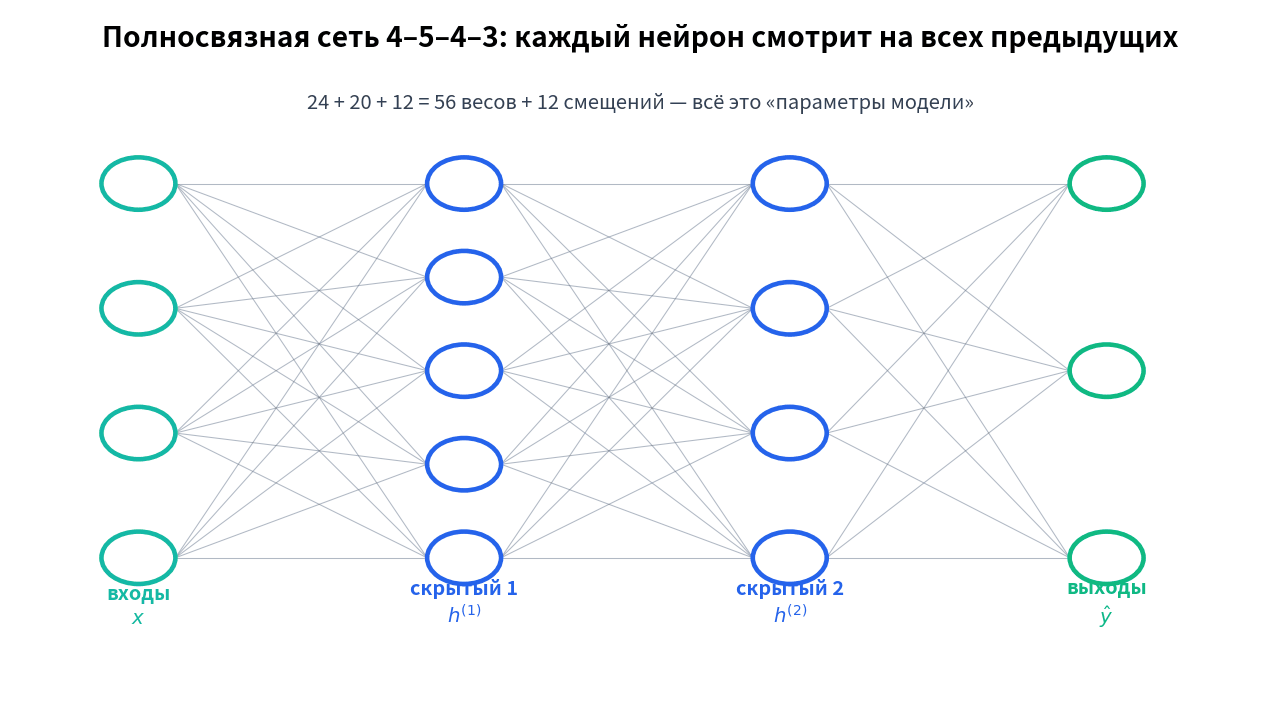

Каждый нейрон скрытого слоя смотрит на **все** выходы предыдущего слоя со своими весами. Параметры сети — это все её веса и смещения: у нашей игрушки их 68, у GPT-класса моделей — миллиарды.

### 3.1. Почему одного слоя мало: задача XOR

Классическая иллюстрация предела линейности — «исключающее или»: класс 1, если входы **разные**. Никакая прямая не разделит «разные углы» от «одинаковых»:


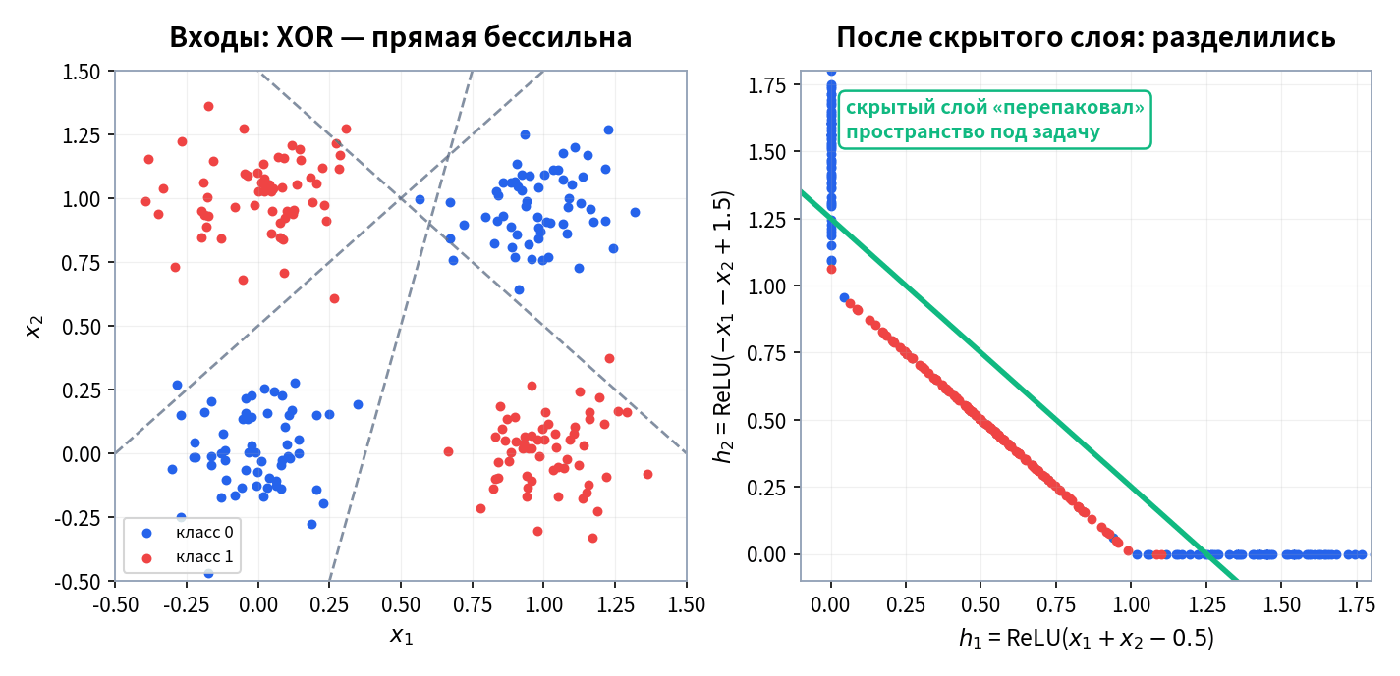

Скрытый слой с ReLU **перепаковал пространство**: в новых координатах $h_1 = \text{ReLU}(x_1 + x_2 - 0.5)$ и $h_2 = \text{ReLU}(-x_1 - x_2 + 1.5)$ классы снова разделяются прямой. В этом и есть вся магия глубины: **каждый слой поворачивает и перегибает пространство так, что к последнему слою классы ложатся по разные стороны линии.**

Два факта для общей картины:

1. **Теорема универсальной аппроксимации** (Цыбенко, 1989): одного скрытого слоя достаточно, чтобы приблизить любую непрерывную функцию. Но слой может понадобиться чудовищно широкий.
2. **Глубина эффективнее ширины**: 10 слоёв по 100 нейронов обычно выразительнее 1 слоя из 1000 — как 10 этажей здания экономнее плоской деревни. Глубина строит **иерархию признаков**: пиксели → штрихи → части объектов → объекты (во всей красе увидим в CNN, лекция 6).


## 4. Как сеть учится: концепция без формул (20–45 мин)

Обучение нейросети — это не магия, а итеративный процесс настройки весов. Он состоит из трёх ключевых идей:

1. **Функция потерь (Loss Function, 损失函数):**  
   Измеряет и показывает,, *«насколько сеть ошиблась»*. Чем меньше значение, тем лучше.
2. **Градиент (梯度, Gradient)**:
   Это направление, в котором ошибка растёт быстрее всего. Нам нужно идти в **противоположную** сторону, чтобы ошибку уменьшить
3. **Градиентный спуск (Gradient Descent, 梯度下降):**  
   **Аналогия:** Вы стоите на склоне горы в густом тумане. Вы не видите всю гору, но можете почувствовать ногой, в какую сторону склон идёт вниз. Вы делаете маленький шаг в эту сторону.  И так повторяете, пока не окажетесь в самой нижней точке (минимум ошибки).
4. **Скорость обучения (Learning Rate, 学习率):**
   Размер вашего шага.  
   - *Слишком большой шаг*: вы перепрыгнете через долину и начнёте скакать по склонам (сеть не сойдётся).
   - *Слишком маленький шаг*: вы будете спускаться вечность (обучение займёт слишком много времени).
6. **Обратное распространение ошибки (Backpropagation, 反向传播):**  
   **Аналогия:** «Разбор полётов». Ошибка вычисляется на выходе, после того как сеть дала неверный ответ, затем сеть идёт *задом наперёд* (**от выхода к входу** ) и говорит каждому нейрону: «Ты внес вот такой вклад в ошибку, чуть-чуть измени свой вес» и корректируем веса каждого нейрона пропорционально тому, насколько он виноват в ошибке.


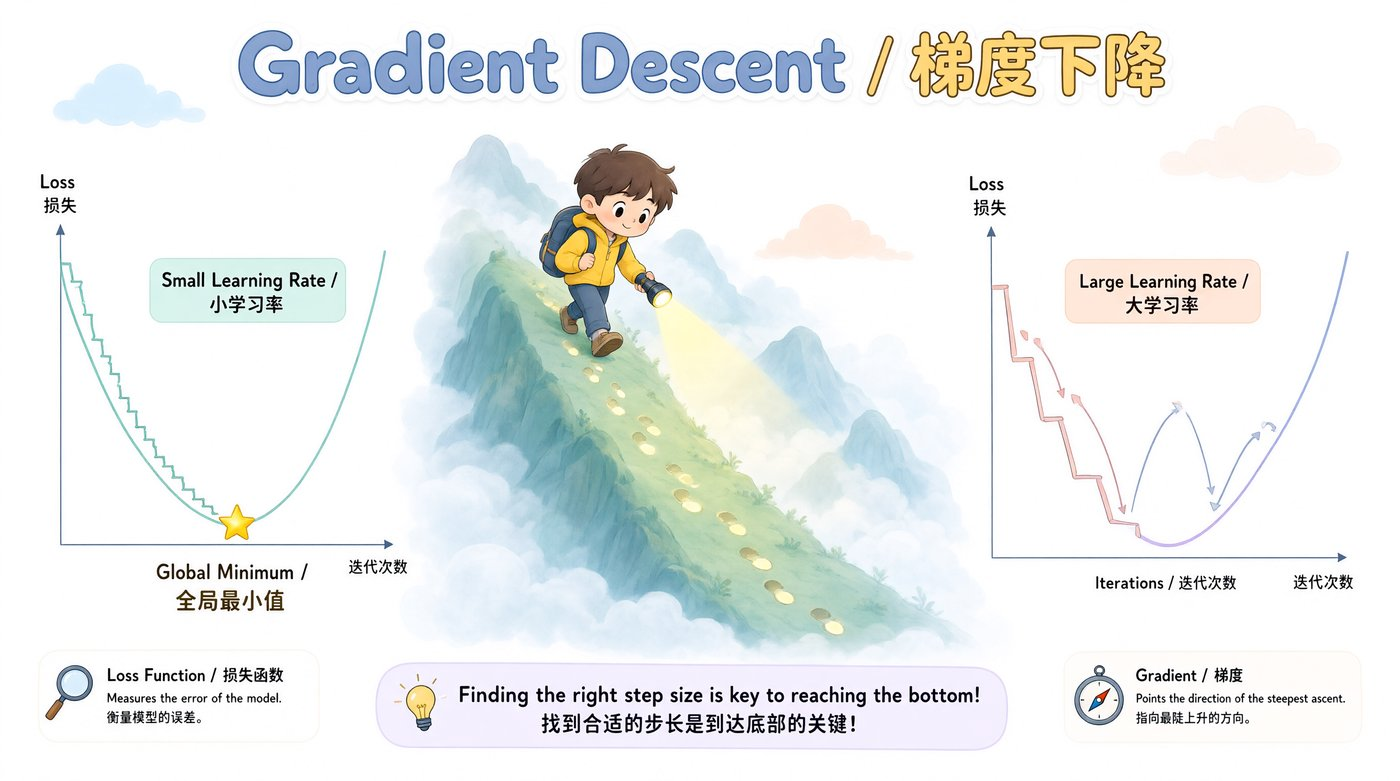
*Рис. 2. Аналогия градиентного спуска: спуск с горы в тумане с разным размером шага (learning rate).*

## 4. Как сеть учится: потери, градиент, обратная волна

### 4.1. Потери — счёт на табло

Обучение = минимизация числа, измеряющего ошибку. **Функция потерь** (loss, 损失函数):

- регрессия: $L = \text{MSE} = \frac{1}{n}\sum (y_i - \hat{y}_i)^2$ — уже знакомая из лекции 4;
- классификация: **кросс-энтропия** $L = -\sum y_i \log \hat{p}_i$ — сильно штрафует уверенные ошибки (сказал «98% это кошка», а это собака → большой штраф).

### 4.2. Градиентный спуск: скатывание по ландшафту

Представим потери как рельеф над пространством весов. В каждой точке **градиент** $\nabla L$ показывает направление самого крутого подъёма. Спускаемся наоборот:

$$w \leftarrow w - \eta \, \nabla L(w)$$

где $\eta$ — **learning rate** (скорость обучения, 学习率). Каждую итерацию — маленький шаг вниз.


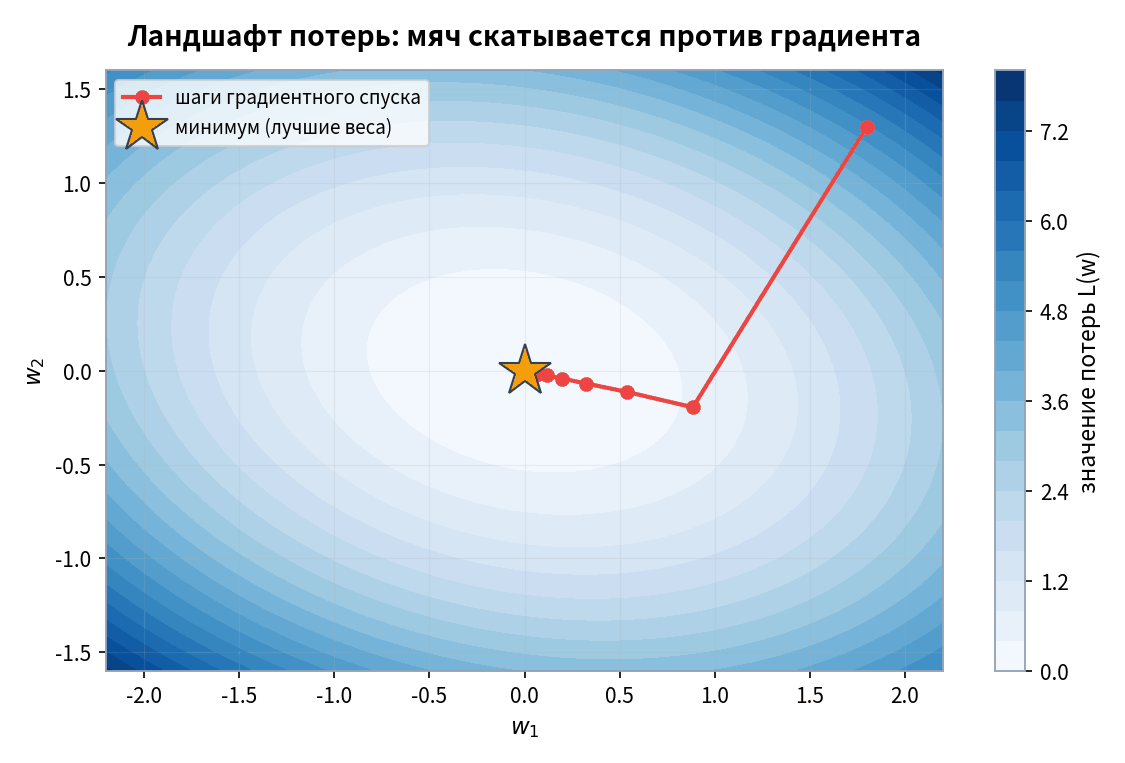


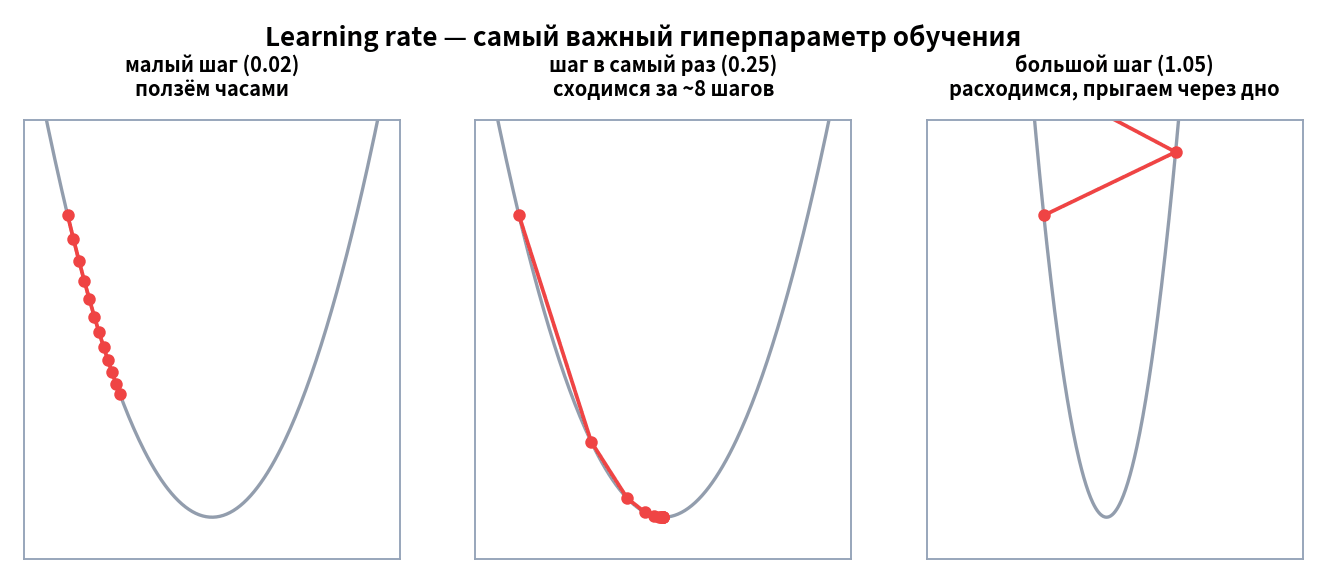

Шаг- Скорость обучения (Learning Rate, 学习率) — гиперпараметр, который чаще всего ломает обучение: слишком мал → ползём неделями; слишком велик → перепрыгиваем дно и расходимся. Практика: стартуют с $10^{-3}$ (Adam) или $10^{-2}$ (SGD) и уменьшают по расписанию, когда потери «застревают».

### 4.3. Backprop: цепное правило на всю сеть

Кто именно виноват в ошибке — вес в первом слое или в последнем? Ответ даёт **обратное распространение** (backpropagation, 反向传播): от потерь назад по слоям, применяя цепное правило $\frac{\partial L}{\partial w_1} = \frac{\partial L}{\partial h} \cdot \frac{\partial h}{\partial w_1}$, вычисляем вклад каждого веса. Механику в деталях даёт курс математического анализа; инженеру важно понимать **что** это даёт: точное направление и величину шага для каждого из миллионов весов за один проход по графу вычислений.


In [ ]:
# Градиентный спуск на параболе L = w^2: минимум в w = 0
def descend(w, eta, шагов):
    путь = [w]
    for _ in range(шагов):
        grad = 2 * w          # производная L = w^2
        w = w - eta * grad    # шаг спуска
        путь.append(w)
    return путь

print("η = 0.2 (осторожный шаг):", [round(w, 3) for w in descend(2.0, 0.2, 8)])
print("η = 1.1 (слишком широкий шаг):", [round(w, 3) for w in descend(2.0, 1.1, 6)])



При η = 0,2 шаги сходятся: **2 → 1,2 → 0,72 → 0,43 → 0,26 → 0,16 → …** — вес плавно катится ко дну долины. При η = 1,1 шаги **раскачиваются и взрываются**: 2 → −2,4 → +2,88 → −3,46 → … — каждая итерация уводит дальше от минимума. Реальные сети делают то же самое, только с миллионами весов одновременно — именно поэтому скорость обучения всегда начинают с консервативных 0,001–0,01.


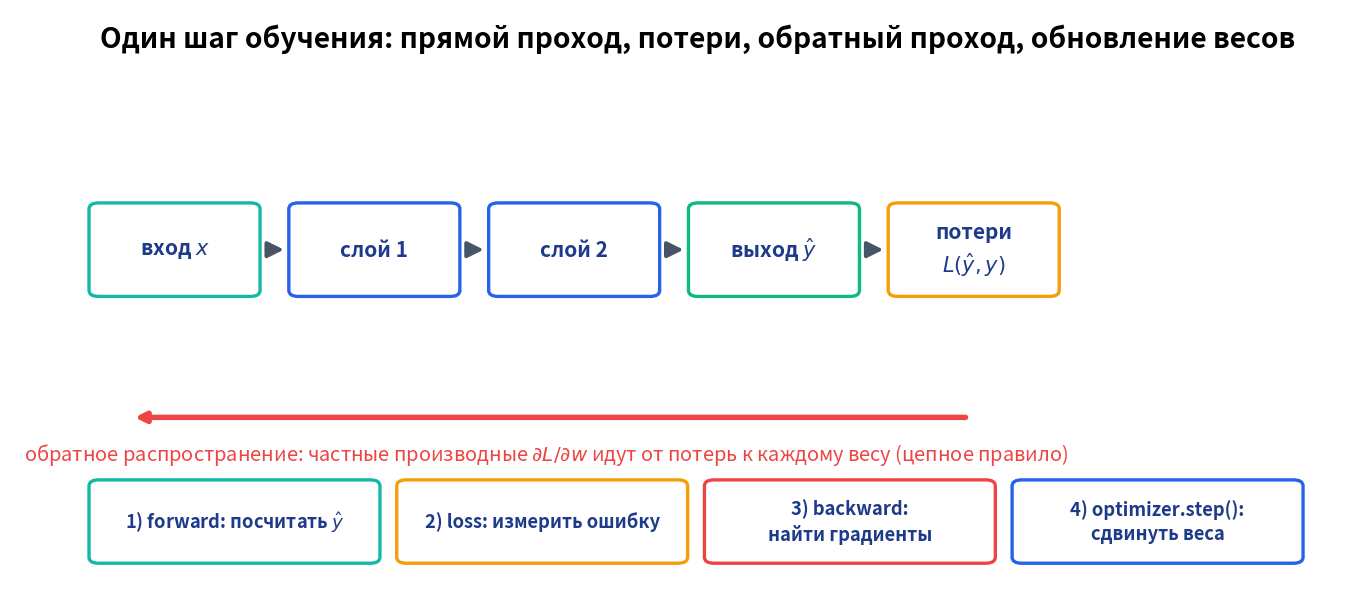

### 4.4. Эпохи, пакеты, SGD и Adam

- **эпоха** (epoch) — один полный проход по всем обучающим данным;
- **мини-пакет** (batch) — 32–256 примеров, по которым считается один шаг: градиент шумный, но дешёвый; шум даже полезен — выпрыгивает из ям-обманок;
- **SGD** — спуск по мини-пакетам; **Adam** — «умный» вариант с индивидуальным шагом для каждого веса (адаптивный момент); дефолт современных задач.


---
## 🎬 Видеоматериалы: нейрон, градиент и backprop
Анимации 3Blue1Brown (рус. озвучка), «Суть матанализа» и разборы градиента и backprop к разделам 1–4.
### 🇷🇺 РУС · русскоязычные видео (10)
| № | Видео | Источник | Длит. | Раздел лекции  | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [Нейросети: #1. Глубокое обучение I [3Blue1Brown]](https://vkvideo.ru/video-55155418_456242620)<br>· ориг.: *But what is a neural network?* | Vert Dider (VK/Rutube) | 18 мин | Л5 §1–3: нейроны, слои, веса и смещения (на примере MNIST)  X |
| 2 | [Нейросети: #2. Глубокое обучение II: градиентный спуск](https://vkvideo.ru/video-55155418_456242659)<br>· ориг.: *Gradient descent, how neural networks learn* | Vert Dider (VK/Rutube) | 20 мин | Л5 §4: функция потерь и градиент  X |
| 3 | [[3Blue1Brown RU] DeepLearning Ч.1. Что же такое нейронная сеть?](https://rutube.ru/video/9da8798d121947a2ce2a9fc2fe657ea8/)<br>· ориг.: *But what is a neural network? (озвучка Alex_Nik)* | Rutube · Alex_Nik | 19 мин | Л5 §1–3: альтернативная озвучка серии  X |
| 4 | [[3Blue1Brown RU] DeepLearning Ч.2. Градиентный спуск: как учатся сети](https://rutube.ru/video/ac51e93eacb8179e8d9c258dc76ecf26/)<br>· ориг.: *Gradient descent (озвучка Alex_Nik)* | Rutube · Alex_Nik | 20 мин | Л5 §4: спуск по функции потерь  X |
| 5 | [[3Blue1Brown RU] DeepLearning Ч.3. Суть метода обратного распространения](https://rutube.ru/video/1efa62f4d186e910d1d44d69949cbfa2/)<br>· ориг.: *What is backpropagation really doing? (озвучка Alex_Nik)* | Rutube · Alex_Nik | 13 мин | Л5 §4.3: backprop на интуиции  X |
| 6 | [[3Blue1Brown RU] DeepLearning Ч.4. Формулы обратного распространения](https://rutube.ru/video/030335d8cc5c90fdc4e4652d7926e88d/)<br>· ориг.: *Backpropagation calculus (озвучка Alex_Nik)* | Rutube · Alex_Nik | 10 мин | Л5 §4.3: цепное правило математически  X |
| 7 | [[3Blue1Brown] Матанализ, Гл.1. Суть матанализа](https://rutube.ru/video/60ae41c0c62470972eb9e52a4d216835/)<br>· ориг.: *Essence of calculus #1* | Rutube · Alex_Nik | 16 мин | Л5 §4: производная = наклон — база градиентного спуска  X |
| 8 | [[3Blue1Brown] Матанализ, Гл.4. Правило произведения и цепное правило](https://rutube.ru/video/b16c7939529c6704c4cdb58f28454de7/)<br>· ориг.: *Essence of calculus #4* | Rutube · Alex_Nik | 15 мин | Л5 §4: цепное правило — сердце backprop  X |
| 9 | [Py #11. Идея обучения НС градиентным алгоритмом](https://rutube.ru/video/4c1f65ab0dc85104034a8fa8a7924983/) | Rutube · SelfEdu | 12 мин | Л5 §4: обучение как поиск минимума  X |
| 10 | [Py #12. Алгоритм back propagation. Пример работы](https://rutube.ru/video/520d1a16d3eb0ee0790e55fee5548625/) | Rutube · SelfEdu | 13 мин | Л5 §4.3: обратное распространение ошибки  X |
### 🇨🇳 中文 · китайскоязычные видео (оригинал в курсиве) (6)
| № | Видео | Источник | Длит. | Раздел лекции  | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [От функции к нейронной сети](https://www.bilibili.com/video/BV1DgxCzREbM?p=1)<br>· ориг.: *【入门篇】从函数到神经网络* | Bilibili (анимакурс) | 9 мин | Л5 §1: от биологии нейрона к арифметике  ✓ |
| 2 | [Градиентный спуск](https://www.bilibili.com/video/BV1Y7411d7Ys?p=3)<br>· ориг.: *03.梯度下降算法* | Bilibili · 刘二大人 | 41 мин | Л5 §4: спуск по функции потерь  ✓ |
| 3 | [Обратное распространение ошибки](https://www.bilibili.com/video/BV1Y7411d7Ys?p=4)<br>· ориг.: *04.反向传播* | Bilibili · 刘二大人 | 46 мин | Л5 §4.3: backpropagation  ✓ |
| 4 | [Многослойный перцептрон](https://www.bilibili.com/video/BV1EY6FBwE8P?p=33)<br>· ориг.: *33.2-多层感知机* | Bilibili · 李沐 | 22 мин | Л5 §3: слои и глубина  ✓ |
| 5 | [Автоматическое дифференцирование (autograd)](https://www.bilibili.com/video/BV1EY6FBwE8P?p=16)<br>· ориг.: *16.1-自动求导-* | Bilibili · 李沐 | 11 мин | Л5 §4: autograd — градиент без ручной работы  ✓ |
| 6 | [Обработка многомерных входов](https://www.bilibili.com/video/BV1Y7411d7Ys?p=7)<br>· ориг.: *07.处理多维特征的输入* | Bilibili · 刘二大人 | 43 мин | Л5 §3: от одного входа к матрице данных  ✓ |
### 🇬🇧 EN · англоязычные видео (6)
| № | Видео | Источник | Длит. | Раздел лекции  | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [Andrew Ng: Нейроны и мозг](https://www.bilibili.com/video/BV1owrpYKEtP?p=39)<br>· ориг.: *39.神经元与大脑 (речь — английская)* | Bilibili · 吴恩达 | 10 мин | Л5 §1: биологическое вдохновение  ✓ |
| 2 | [Andrew Ng: Слои нейронной сети](https://www.bilibili.com/video/BV1owrpYKEtP?p=42)<br>· ориг.: *42.神经网络层 (речь — английская)* | Bilibili · 吴恩达 | 9 мин | Л5 §3: слои и forward propagation  ✓ |
| 3 | [StatQuest: градиентный спуск шаг за шагом](https://www.bilibili.com/video/BV1XW421F7M4/)<br>· ориг.: *【官方双语】零基础梯度下降法，手把手教你优化损失函数！* | Bilibili · StatQuest | 23 мин | Л5 §4: как сеть учится — оптимизация  ✓ |
| 4 | [StatQuest: обратное распространение — супер-простое объяснение](https://www.bilibili.com/video/BV1at421L7DS/)<br>· ориг.: *【官方双语】反向传播超简明教程，解析神经网络参数优化的核心技术* | Bilibili · StatQuest | 17 мин | Л5 §4: backprop без страха  ✓ |
| 5 | [StatQuest: строим нейросеть на PyTorch](https://www.bilibili.com/video/BV1um41127Fo/)<br>· ориг.: *【官方双语】一步一步带你用PyTorch构建神经网络！* | Bilibili · StatQuest | 23 мин | Л5: PyTorch на практике  ✓ |
| 6 | [StatQuest: L1-регуляризация (Lasso)](https://www.bilibili.com/video/BV12bCzYBEBM/)<br>· ориг.: *【官方双语】一个视频带你看懂L1正则化（Lasso回归）！* | Bilibili · StatQuest | 8 мин | Л5 §5: регуляризация против переобучения  ✓ |

> 📄 Полная версия с идентичными ссылками: PDF «Видеоматериалы по 5 модулям и 10 лекциям», глава соответствующего модуля.

## 5. Переобучение и четыре способа с ним бороться
### ⚠️ Переобучение (过拟合, Overfitting)
**Аналогия с баскетболистом:** Игрок тренируется **только в одном зале**, привыкая к конкретному освещению, высоте кольца и скрипу пола. На своей площадке он забивает 95% бросков, но на **чужой площадке** — только 40%. Он запомнил условия, а не научился играть.

**Как распознать на графике:**
- 🔵 **Ошибка на обучении (Train Loss):** steadily падает.
- 🔴 **Ошибка на тесте (Test Loss):** сначала падает, а потом **начинает расти**.

Это сигнал: модель начала запоминать обучающие примеры вместо того, чтобы находить общие закономерности.

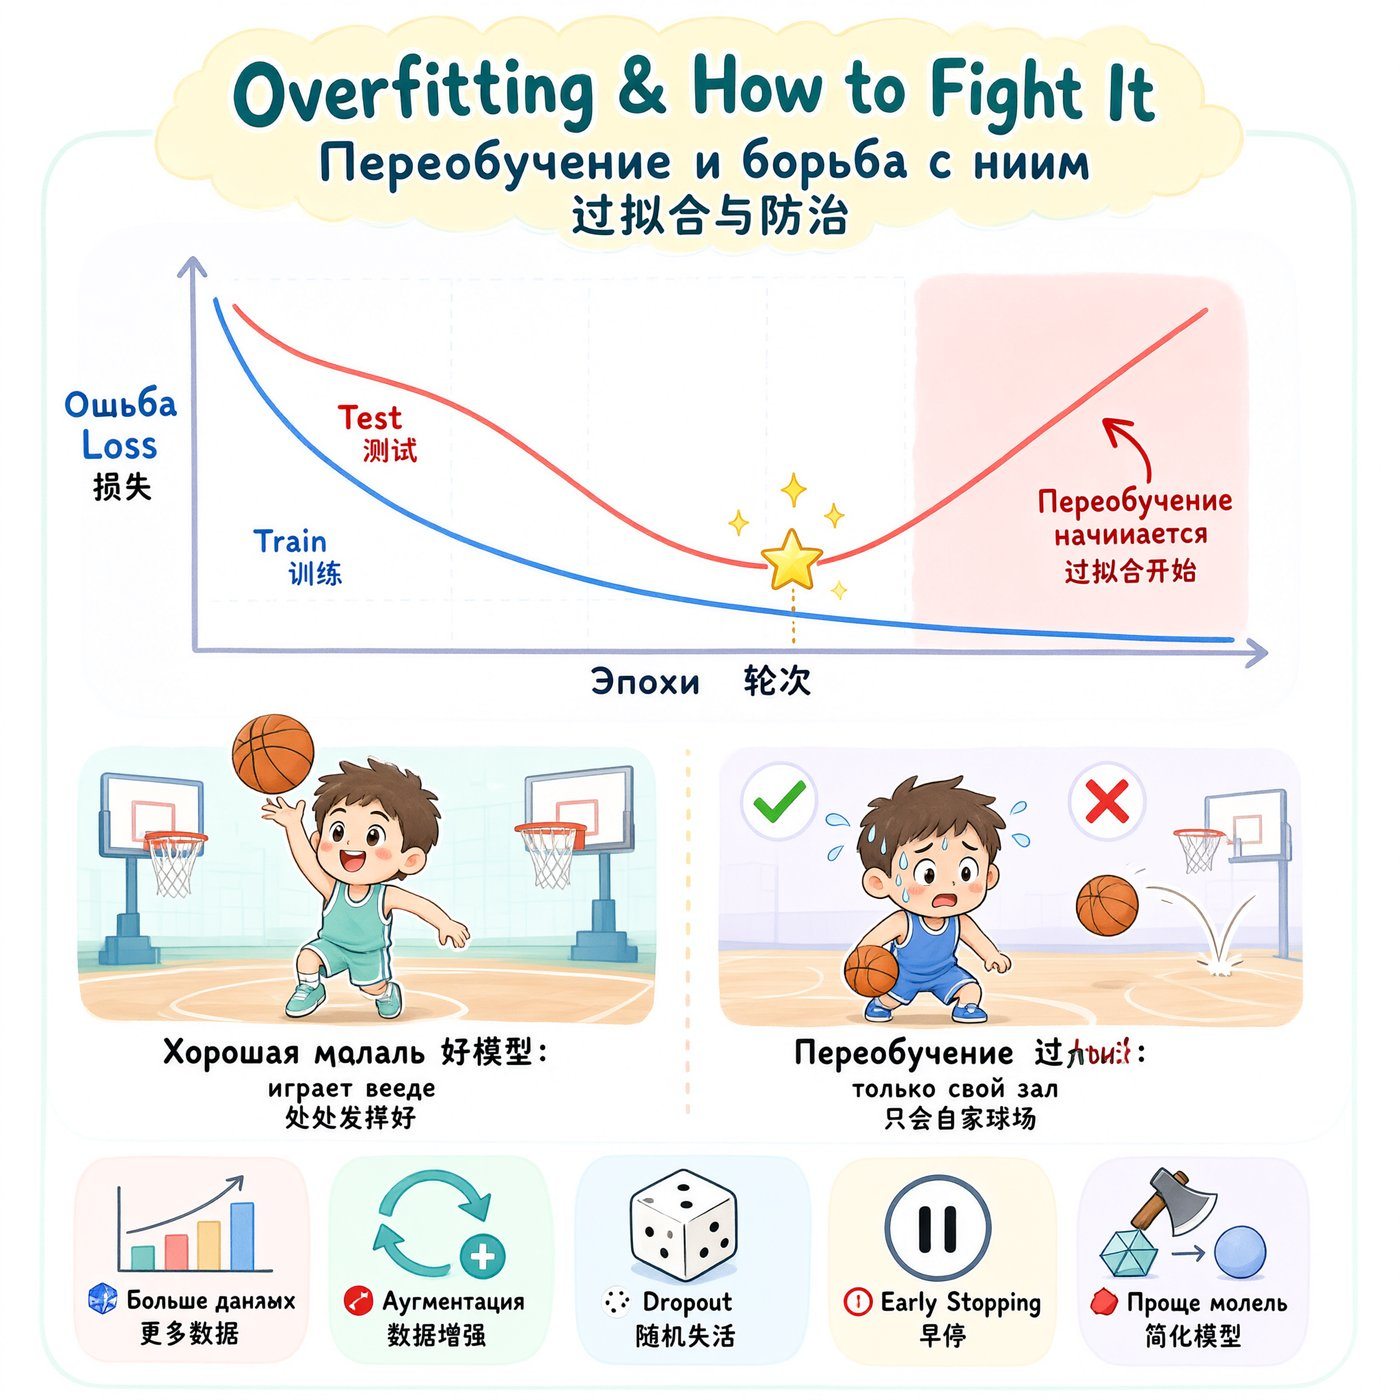
*Рис. 4. Классический признак переобучения: train loss падает, а test loss растёт после определённой эпохи.*

### 🛡️ 5 способов борьбы с переобучением:

1. **📈 Больше данных (更多数据):** Чем больше примеров, тем сложнее их запомнить. Самый эффективный способ!
2. **🔄 Аугментация (数据增强):** Искусственно увеличиваем обучающие данные. Для картинок: повороты, отражения, сдвиги, изменение яркости. *Пример: одна фотография кошки даёт 10 разных примеров.*
3. **🎲 Dropout (随机失活):** Во время обучения **случайно выключаем** часть нейронов (например, 50%). Сеть не может полагаться на конкретные нейроны и учит более устойчивые признаки.
4. **⏸️ Ранняя остановка (Early Stopping, 早停):** Следим за ошибкой на тесте. Как только она начинает расти — останавливаем обучение и возвращаемся к лучшей модели.
5. **🪓 Более простая модель (简化模型):** Меньше слоёв, меньше нейронов. У сложной модели слишком много «карманов» для запоминания шума.

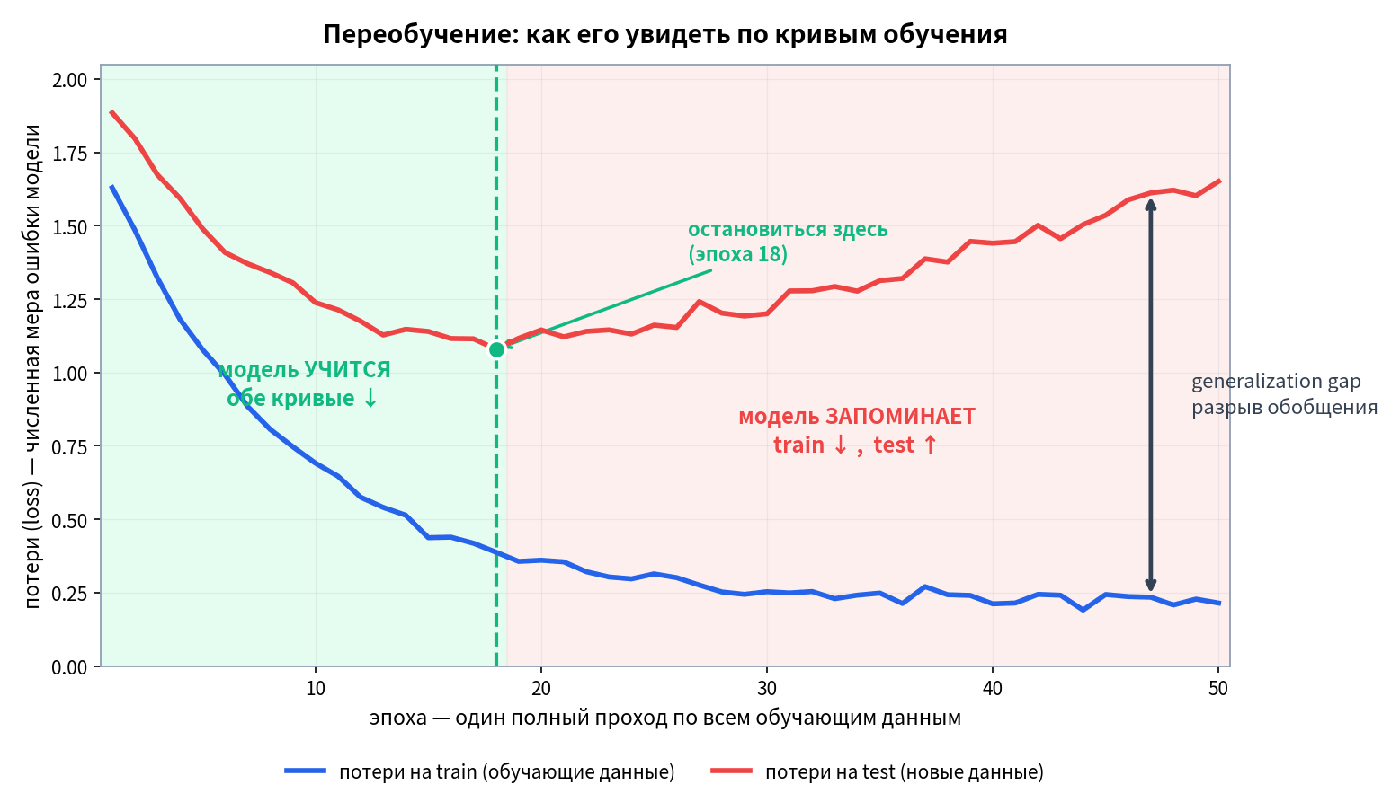

**Как читать этот график.** На нём сразу две кривые потерь. **Синяя** — ошибка на *обучающей* выборке (train): на примерах, которые сеть видит каждую эпоху. **Красная** — ошибка на *тестовой* выборке (test): на новых данных, которых в обучении вообще не было. Это и есть «экзамен» — проверка, чему модель *реально научилась*, а не что заучила.

Пока **обе кривые идут вниз** (зелёная зона) — модель ловит закономерность, и на новых данных тоже становится лучше. Но наступает момент, отмеченный пунктиром, когда **красная кривая разворачивается вверх**, а синяя продолжает падать (красная зона). Это и есть **переобучение**: сеть перестала понимать суть и начала *заучивать конкретные обучающие примеры наизусть* — вместе со случайным шумом в них. На «тренировочном тесте» она почти идеальна (train → 0), а на «настоящем экзамене» ошибается всё сильнее (test ↑).

Расстояние между кривыми справа — это **generalization gap**, разрыв обобщения: чем он шире, тем хуже модель переносит знания на новое. Пунктирная линия показывает точку, где обучение стоило **остановить** — это и есть самое простое лекарство. Ниже — вся «аптечка» целиком.


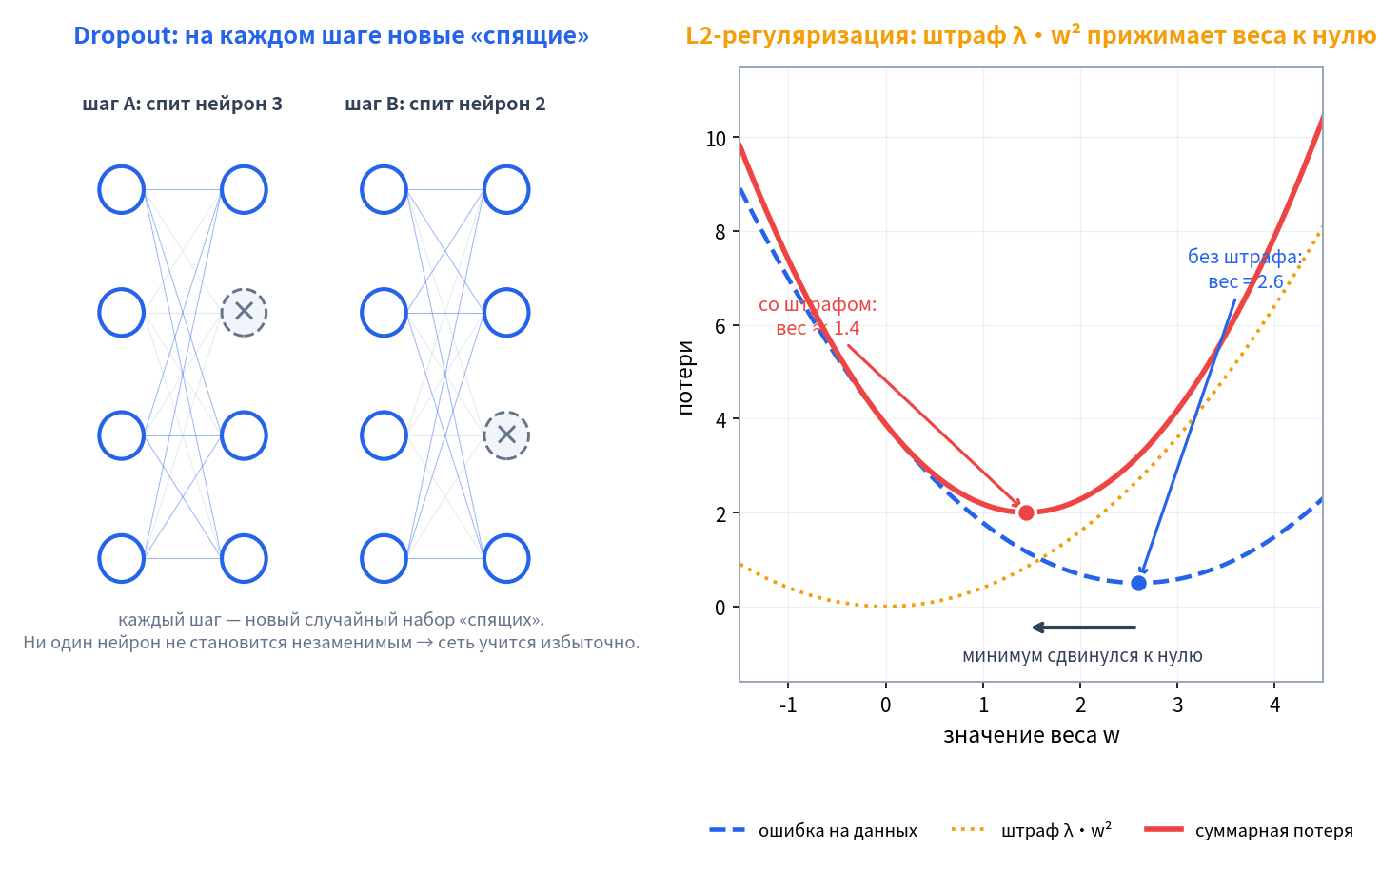

Из пяти средств аптечки **два — «активные»** (встроены прямо в обучение сети): **Dropout** и **L2-регуляризация**. Разберём, как каждое работает — им посвящён рисунок выше.

### Dropout — «не позволяй никому стать незаменимым»

На каждом шаге обучения случайно отключается доля $p$ нейронов (обычно $p=0.3\ldots0.5$) в скрытых слоях. Отключённый нейрон на этом шаге не передаёт сигнал и не обновляет веса — будто его вообще нет. На следующем шаге «спят» уже *другие* нейроны (на рисунке слева — шаг A и шаг B с разными «спящими»).

Зачем это нужно? Без dropout в сети часто появляется один-два «сильных» нейрона, на которые все остальные начинают полагаться. Dropout ломает эту привычку: раз любой нейрон может «уснуть» в любой момент, сети приходится учить *избыточные* признаки и распределять знания по многим нейронам. В PyTorch — одна строчка: `nn.Dropout(p=0.4)`.

### L2-регуляризация — «не отращивай большие веса»

К обычной потере добавляется штраф $\lambda\sum w^2$ — сумма квадратов всех весов, умноженная на коэффициент $\lambda$. Чем больше вес по модулю, тем сильнее за него штраф. Поэтому оптимизатору выгоднее держать веса *умеренными*, даже если большой вес немного уменьшил бы ошибку на обучающих данных.

На рисунке справа это видно наглядно. **Синяя пунктирная** кривая — ошибка на данных — имеет минимум при $w=2.6$. **Оранжевая** кривая — штраф $\lambda w^2$ — растёт от нуля. **Красная** сплошная — суммарная потеря = данные + штраф — получает минимум при $w\approx 1.4$: вес «поджался» к нулю. Стрелка внизу показывает сдвиг минимума. В PyTorch: `optimizer = Adam(..., weight_decay=1e-4)`.

### Остальные три средства — «пассивные»

| Средство | Когда применять |
|---|---|
| **Больше данных / аугментация** | повороты/сдвиги/шум картинок (лекция 6) — самый честный способ: покажите модели другие грани мира |
| **Ранняя остановка** | следить за test-потерями и стоп, когда они поползли вверх (см. график выше) |
| **Меньше сеть** | если данных мало — просто сократить слои/нейроны; ёмкость модели должна соответствовать количеству данных |

**Правило памяти:** ёмкость модели $\leftrightarrow$ количество данных. Миллион весов на 100 примеров — всегда переобучение.


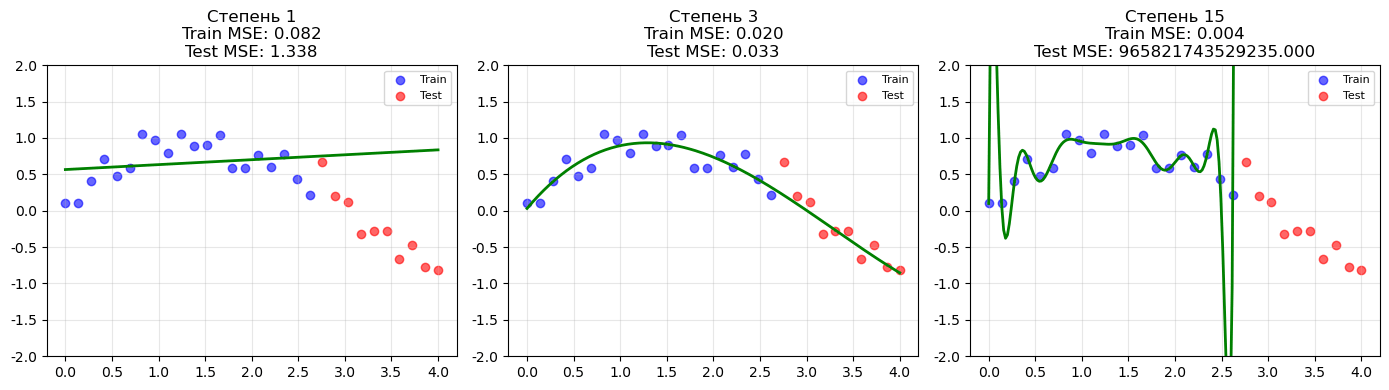

💡 Степень 1: недообучение (欠拟合) — модель слишком простая
💡 Степень 3: хороший баланс
💡 Степень 15: ПЕРЕОБУЧЕНИЕ (过拟合) —_train MSE очень низкий, test MSE огромный!


In [ ]:
# Демонстрация переобучения: полиномиальная регрессия
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Генерируем данные: синусоида + шум
np.random.seed(42)
X = np.linspace(0, 4, 30).reshape(-1, 1)
y = np.sin(X).ravel() + np.random.randn(30) * 0.2

# Делим на обучение и тест
X_train, X_test = X[:20], X[20:]
y_train, y_test = y[:20], y[20:]

degrees = [1, 3, 15]  # степени полинома: 1=прямая, 3=хорошо, 15=переобучение
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, degree in zip(axes, degrees):
    # Создаём полиномиальные признаки
    poly = PolynomialFeatures(degree)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    # Обучаем линейную регрессию
    model = LinearRegression().fit(X_train_poly, y_train)

    # Считаем ошибки
    train_err = mean_squared_error(y_train, model.predict(X_train_poly))
    test_err = mean_squared_error(y_test, model.predict(X_test_poly))

    # Рисуем
    X_plot = np.linspace(0, 4, 200).reshape(-1, 1)
    X_plot_poly = poly.transform(X_plot)

    ax.scatter(X_train, y_train, color='blue', alpha=0.6, label='Train')
    ax.scatter(X_test, y_test, color='red', alpha=0.6, label='Test')
    ax.plot(X_plot, model.predict(X_plot_poly), color='green', linewidth=2)
    ax.set_title(f"Степень {degree}\nTrain MSE: {train_err:.3f}\nTest MSE: {test_err:.3f}")
    ax.set_ylim(-2, 2)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("💡 Степень 1: недообучение (欠拟合) — модель слишком простая")
print("💡 Степень 3: хороший баланс")
print("💡 Степень 15: ПЕРЕОБУЧЕНИЕ (过拟合) —_train MSE очень низкий, test MSE огромный!")

ЧАСТЬ 1: ОБУЧЕНИЕ МОДЕЛИ (5 шагов)
Эпоха 1/5 | Средняя потеря: 0.6944
Эпоха 2/5 | Средняя потеря: 0.7074
Эпоха 3/5 | Средняя потеря: 0.6976
Эпоха 4/5 | Средняя потеря: 0.6922
Эпоха 5/5 | Средняя потеря: 0.6811

ЧАСТЬ 2: ПРЕДСКАЗАНИЕ НА НОВЫХ ДАННЫХ
🔮 Новые данные (shape): torch.Size([3, 10])
🎯 Вероятности классов:
   Пример 1: Класс 0 = 0.5924, Класс 1 = 0.4076
   Пример 2: Класс 0 = 0.3835, Класс 1 = 0.6165
   Пример 3: Класс 0 = 0.4019, Класс 1 = 0.5981
✅ Предсказанные классы: [0, 1, 1]

ЧАСТЬ 3: ВИЗУАЛИЗАЦИЯ ПЕРЕОБУЧЕНИЯ (过拟合)


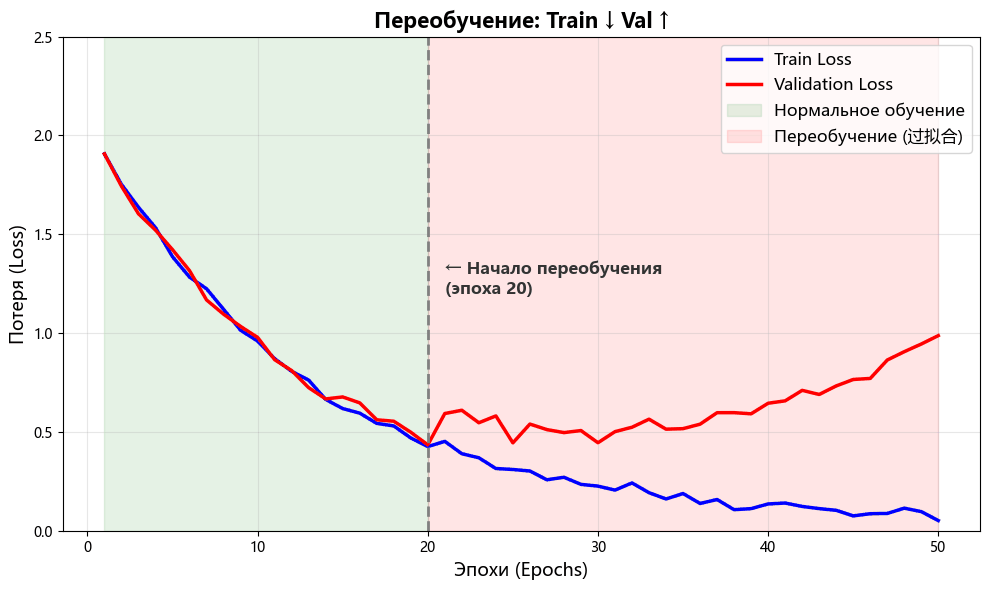


📌 Вывод: До эпохи 20 модель учится, после — начинает запоминать шум.


In [ ]:
# ==========================================
# ПОЛНЫЙ ПРИМЕР: Обучение → Предсказание → График переобучения
# ==========================================
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt

# 1. НАСТРОЙКА ШРИФТОВ (Убирает предупреждения Glyph missing)
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

print("="*50)
print("ЧАСТЬ 1: ОБУЧЕНИЕ МОДЕЛИ (5 шагов)")
print("="*50)

# Создаем искусственные данные
X_dummy = torch.randn(200, 10)
y_dummy = torch.randint(0, 2, (200,))
dataset = TensorDataset(X_dummy, y_dummy)
loader = DataLoader(dataset, batch_size=32, shuffle=True)

model = nn.Sequential(nn.Linear(10, 5), nn.ReLU(), nn.Linear(5, 2))
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

for epoch in range(5):
    epoch_loss = 0.0
    for xb, yb in loader:
        optimizer.zero_grad()      # Шаг 1
        logits = model(xb)         # Шаг 2
        loss = loss_fn(logits, yb) # Шаг 3
        loss.backward()            # Шаг 4
        optimizer.step()           # Шаг 5
        epoch_loss += loss.item()
    print(f"Эпоха {epoch+1}/5 | Средняя потеря: {epoch_loss/len(loader):.4f}")

print("\n" + "="*50)
print("ЧАСТЬ 2: ПРЕДСКАЗАНИЕ НА НОВЫХ ДАННЫХ")
print("="*50)

model.eval()  # Обязательно перед инференсом!
new_data = torch.randn(3, 10)

with torch.no_grad():  # Экономим память и время
    logits = model(new_data)
    probabilities = torch.softmax(logits, dim=1)
    predictions = logits.argmax(dim=1)

print(f"🔮 Новые данные (shape): {new_data.shape}")
print("🎯 Вероятности классов:")
for i, prob in enumerate(probabilities):
    print(f"   Пример {i+1}: Класс 0 = {prob[0]:.4f}, Класс 1 = {prob[1]:.4f}")
print(f"✅ Предсказанные классы: {predictions.tolist()}")

print("\n" + "="*50)
print("ЧАСТЬ 3: ВИЗУАЛИЗАЦИЯ ПЕРЕОБУЧЕНИЯ (过拟合)")
print("="*50)

np.random.seed(42)
epochs = np.arange(1, 51)
train_loss = 2.0 * np.exp(-0.08 * epochs) + 0.05 + np.random.normal(0, 0.02, 50)
val_loss = 2.0 * np.exp(-0.08 * epochs) + 0.05 + 0.15 * np.exp(0.06 * (epochs - 20)) * (epochs > 20) + np.random.normal(0, 0.03, 50)

plt.figure(figsize=(10, 6))
plt.plot(epochs, train_loss, 'b-', linewidth=2.5, label='Train Loss')
plt.plot(epochs, val_loss, 'r-', linewidth=2.5, label='Validation Loss')

overfit_epoch = 20
plt.axvline(x=overfit_epoch, color='gray', linestyle='--', linewidth=2)
plt.text(overfit_epoch + 1, 1.2, f'← Начало переобучения\n(эпоха {overfit_epoch})',
         fontsize=12, fontweight='bold', color='#333')

plt.fill_betweenx([0, 2.5], 1, overfit_epoch, alpha=0.1, color='green', label='Нормальное обучение')
plt.fill_betweenx([0, 2.5], overfit_epoch, 50, alpha=0.1, color='red', label='Переобучение (过拟合)')

plt.xlabel('Эпохи (Epochs)', fontsize=13)
plt.ylabel('Потеря (Loss)', fontsize=13)
plt.title('Переобучение: Train ↓ Val ↑', fontsize=15, fontweight='bold')
plt.legend(fontsize=12, loc='upper right')
plt.grid(True, alpha=0.3)
plt.ylim(0, 2.5)
plt.tight_layout()
plt.show()

print("\n📌 Вывод: До эпохи 20 модель учится, после — начинает запоминать шум.")

🎨 Генерация данных...
🚀 Начало обучения...
✅ Epoch 1/6 completed
✅ Epoch 2/6 completed
✅ Epoch 3/6 completed
✅ Epoch 4/6 completed
✅ Epoch 5/6 completed
✅ Epoch 6/6 completed


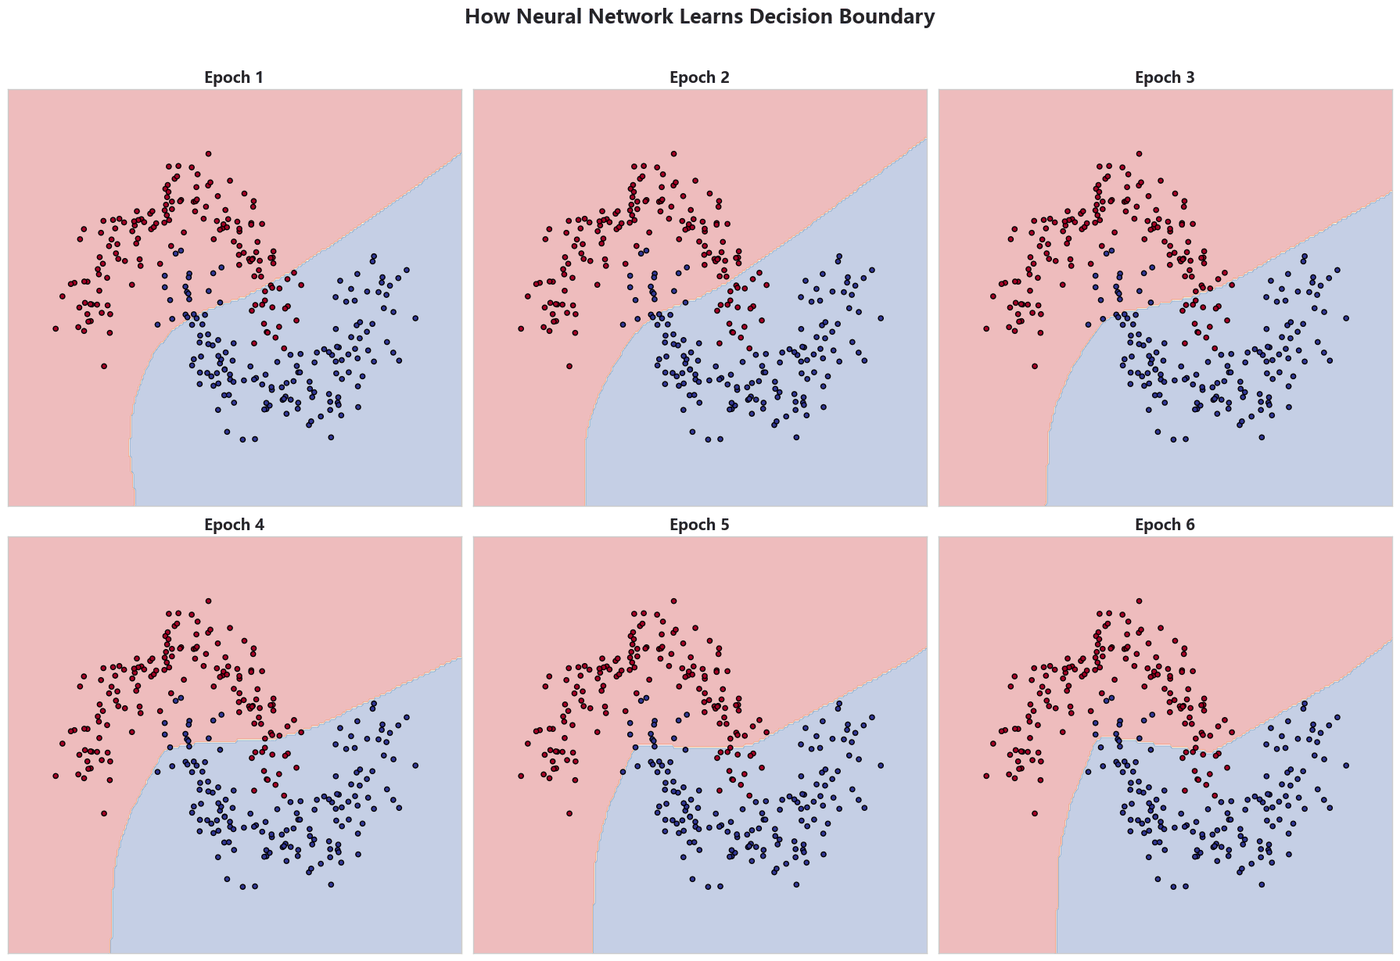


🔮 PART 2: PREDICTION ON NEW DATA
Point (+0.0, +1.0) → Class 0 (confidence: 97.19%)
Point (+1.5, -0.5) → Class 1 (confidence: 99.63%)
Point (-0.5, +0.0) → Class 0 (confidence: 71.57%)

📉 PART 3: OVERFITTING DEMO


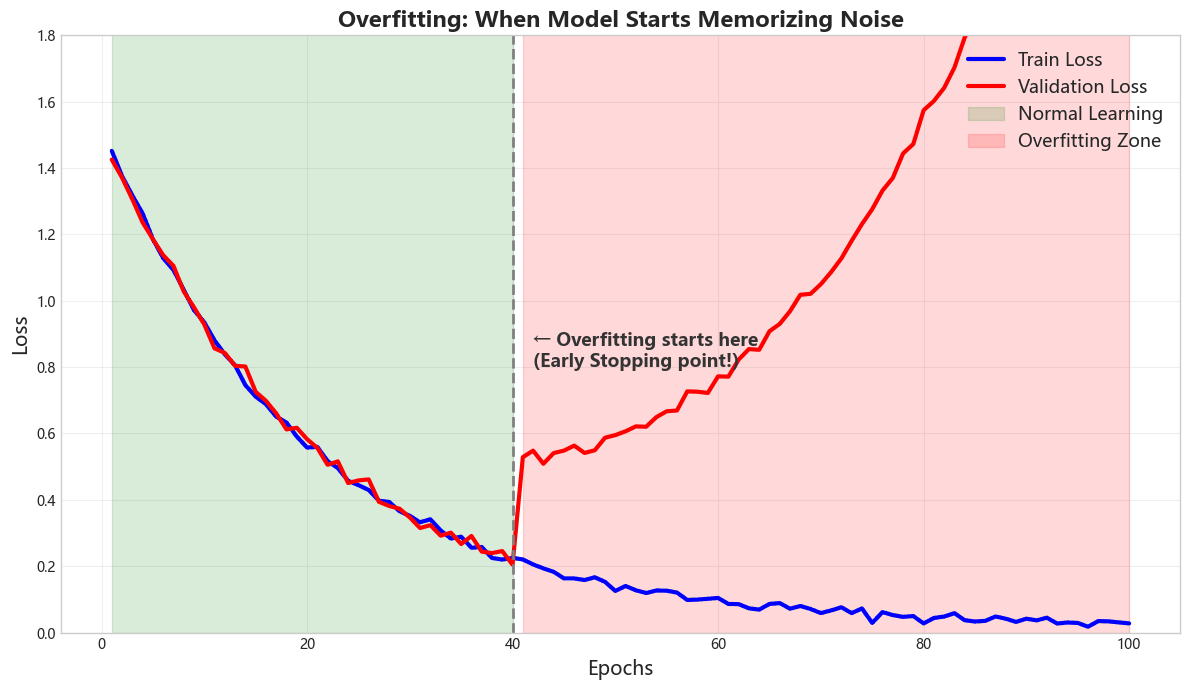


💡 Key Takeaway:
• Before epoch 40: model learns general patterns
• After epoch 40: model memorizes noise in training data
• Solution: Early Stopping, Dropout, or more data!


In [ ]:
# ==========================================
# НАГЛЯДНЫЙ ПРИМЕР: Классификация 2D точек + Переобучение
# ==========================================
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

# Настройка стиля для более красивых графиков
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

print("🎨 Генерация данных...")
# Создаем "лунные" данные - нелинейно разделимые
X_np, y_np = make_moons(n_samples=300, noise=0.15, random_state=42)
X_train = torch.tensor(X_np, dtype=torch.float32)
y_train = torch.tensor(y_np, dtype=torch.long)

dataset = TensorDataset(X_train, y_train)
loader = DataLoader(dataset, batch_size=32, shuffle=True)

# Создание модели
model = nn.Sequential(
    nn.Linear(2, 16),   # Вход: 2 координаты (x, y)
    nn.ReLU(),
    nn.Linear(16, 16),
    nn.ReLU(),
    nn.Linear(16, 2)    # Выход: 2 класса
)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# Обучение с визуализацией каждой эпохи
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

print("🚀 Начало обучения...")
for epoch in range(6):
    model.train()
    for xb, yb in loader:
        optimizer.zero_grad()
        logits = model(xb)
        loss = loss_fn(logits, yb)
        loss.backward()
        optimizer.step()

    # Рисуем decision boundary после каждой эпохи
    ax = axes[epoch]
    h = 0.02
    x_min, x_max = X_np[:, 0].min() - 0.5, X_np[:, 0].max() + 0.5
    y_min, y_max = X_np[:, 1].min() - 0.5, X_np[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

    with torch.no_grad():
        grid_tensor = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
        Z = model(grid_tensor).argmax(dim=1).numpy().reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap='RdYlBu')
    ax.scatter(X_np[:, 0], X_np[:, 1], c=y_np, cmap='RdYlBu', edgecolors='k', s=20)
    ax.set_title(f'Epoch {epoch+1}', fontsize=14, fontweight='bold')
    ax.set_xticks([])
    ax.set_yticks([])

    print(f"✅ Epoch {epoch+1}/6 completed")

plt.suptitle('How Neural Network Learns Decision Boundary', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Предсказание на новых точках
print("\n" + "="*60)
print("🔮 PART 2: PREDICTION ON NEW DATA")
print("="*60)

model.eval()
new_points = torch.tensor([[0.0, 1.0], [1.5, -0.5], [-0.5, 0.0]], dtype=torch.float32)

with torch.no_grad():
    probs = torch.softmax(model(new_points), dim=1)
    preds = probs.argmax(dim=1)

for i, (point, prob, pred) in enumerate(zip(new_points, probs, preds)):
    print(f"Point ({point[0]:+.1f}, {point[1]:+.1f}) → Class {pred.item()} "
          f"(confidence: {prob[pred].item():.2%})")

# График переобучения
print("\n" + "="*60)
print("📉 PART 3: OVERFITTING DEMO")
print("="*60)

np.random.seed(42)
epochs_range = np.arange(1, 101)
train_loss_curve = 1.5 * np.exp(-0.05 * epochs_range) + 0.02 + np.random.normal(0, 0.01, 100)
val_loss_curve = 1.5 * np.exp(-0.05 * epochs_range) + 0.02 + \
                 0.3 * np.exp(0.04 * (epochs_range - 40)) * (epochs_range > 40) + \
                 np.random.normal(0, 0.015, 100)

plt.figure(figsize=(12, 7))
plt.plot(epochs_range, train_loss_curve, 'b-', linewidth=3, label='Train Loss')
plt.plot(epochs_range, val_loss_curve, 'r-', linewidth=3, label='Validation Loss')

plt.axvline(x=40, color='gray', linestyle='--', linewidth=2)
plt.text(42, 0.8, '← Overfitting starts here\n(Early Stopping point!)',
         fontsize=13, fontweight='bold', color='#333')

plt.fill_between(epochs_range, 0, 2, where=(epochs_range <= 40),
                 alpha=0.15, color='green', label='Normal Learning')
plt.fill_between(epochs_range, 0, 2, where=(epochs_range > 40),
                 alpha=0.15, color='red', label='Overfitting Zone')

plt.xlabel('Epochs', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.title('Overfitting: When Model Starts Memorizing Noise', fontsize=16, fontweight='bold')
plt.legend(fontsize=13, loc='upper right')
plt.grid(True, alpha=0.3)
plt.ylim(0, 1.8)
plt.tight_layout()
plt.show()

print("\n💡 Key Takeaway:")
print("• Before epoch 40: model learns general patterns")
print("• After epoch 40: model memorizes noise in training data")
print("• Solution: Early Stopping, Dropout, or more data!")

## 6. PyTorch: рабочая площадка глубокого обучения

Писать backprop руками — увлекательно один раз. Для работы существуют фреймворки:


Два главных фреймворка: PyTorch и TensorFlow

### Что такое фреймворк глубокого обучения?
Фреймворк — это библиотека, которая берёт на себя тяжёлую работу:
- операции с тензорами;
- автоматическое вычисление градиентов — **autograd**;
- обучение на GPU;
- слои нейросетей;
- оптимизаторы;
- загрузку данных;
- сохранение и загрузку моделей.

Главные фреймворки в мире:
1. **PyTorch** — очень популярен в исследованиях и обучении. Код похож на обычный Python, граф вычисляется динамически. Удобно отлаживать.
2. **TensorFlow** — популярен в промышленности. В TensorFlow 2.x высокоуровневый API **Keras** позволяет писать модели очень коротко. Есть инструменты для мобильных устройств и серверного развёртывания.

В нашем курсе используем **PyTorch**: код понятнее для начинающих, а идеи у всех фреймворков общие. Если студент поймёт PyTorch, он быстро разберётся и в TensorFlow.

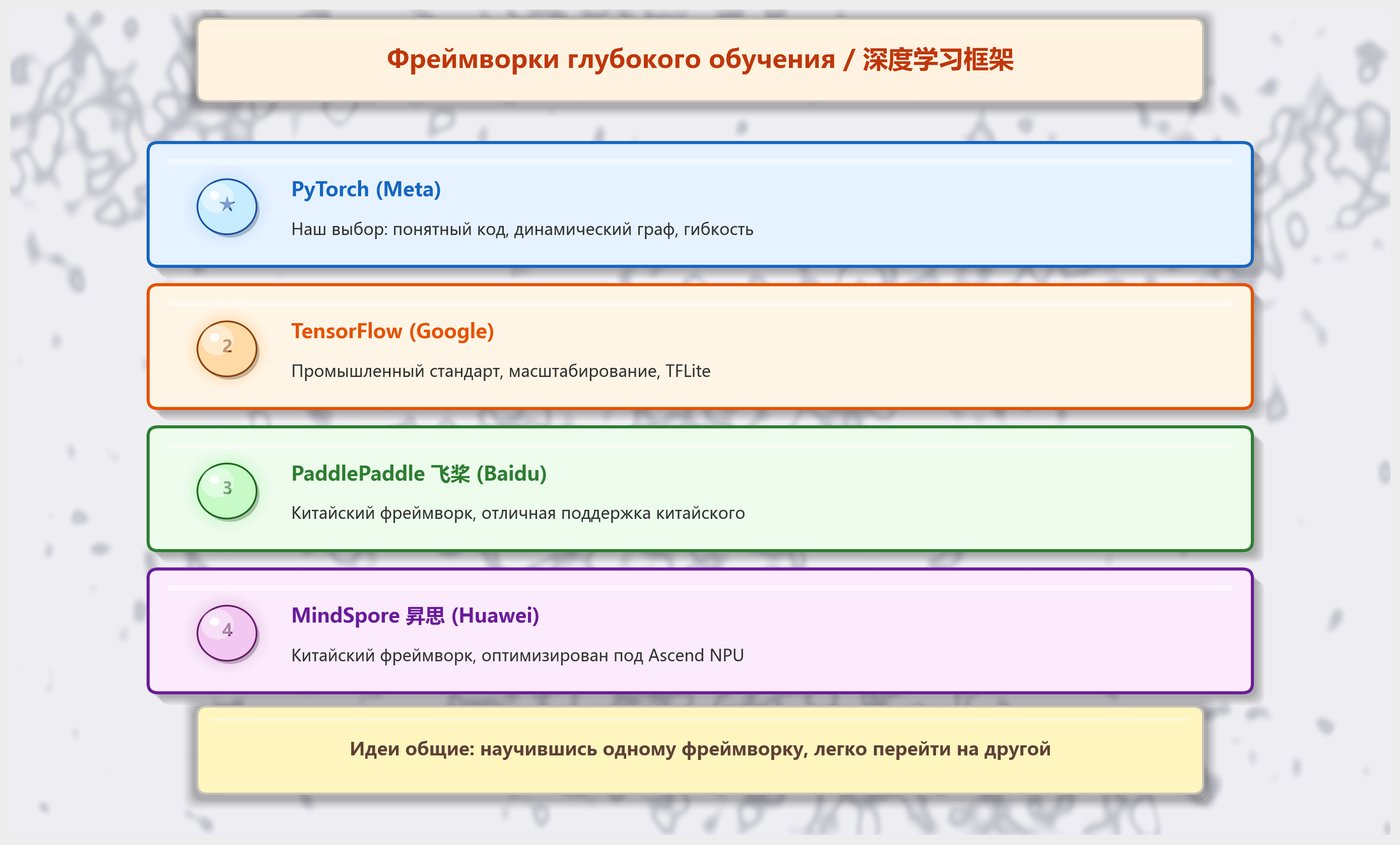
### Сравнение в простой таблице

| | PyTorch | TensorFlow / Keras |
|---|---|---|
| Стиль кода | Pythonic, явный цикл обучения | Часто высокоуровневый `fit()` |
| Граф | динамический, «на лету» | динамический в TF 2.x |
| Для обучения и исследований | очень удобен | тоже удобен |
| Для промышленного развёртывания | есть, но исторически сильнее в research | сильные инструменты: TF Serving, TFLite |
| Цикл обучения | обычно пишем сами | часто скрыт внутри `model.fit()` |

### Отечественные китайские фреймворки
Стоит упомянуть:
- **PaddlePaddle (飞桨)** — фреймворк от Baidu;
- **MindSpore (昇思)** — фреймворк от Huawei.

Идеи там те же: тензоры, слои, градиенты, оптимизаторы, цикл обучения. Поэтому после PyTorch студентам будет проще освоить и их.

> 💡 **Главная мысль блока:** не нужно учить все фреймворки сразу. Нужно понять общие принципы: тензор → модель → потеря → градиент → шаг оптимизатора

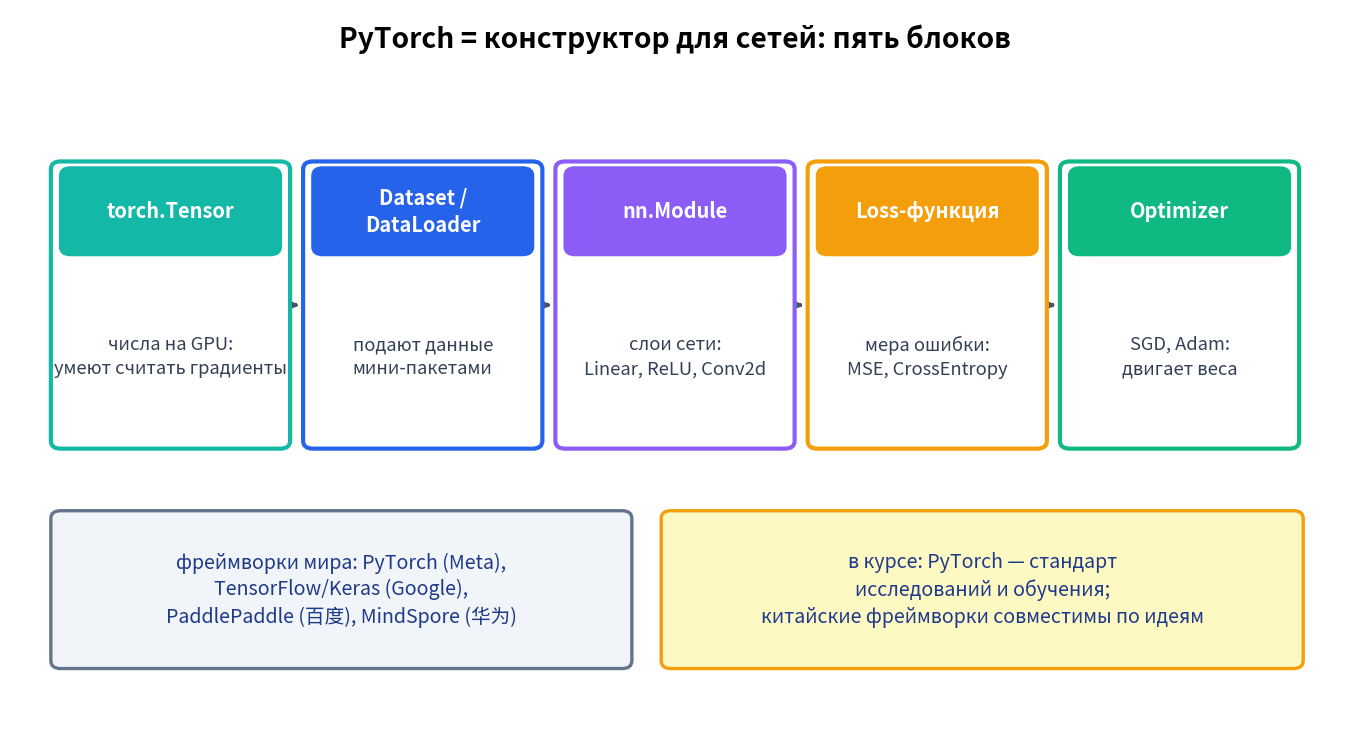

**Почему PyTorch в нашем курсе:** стандарт научных публикаций и университетских курсов, дружелюбный «python-подобный» стиль, огромная экосистема. Для будущей работы в китайских компаниях полезно знать и отечественные фреймворки: **PaddlePaddle** (Baidu) и **MindSpore** (Huawei) — идеи (тензоры, автоград, слои, оптимизаторы) ровно те же, отличается синтаксис.

Минимальный словарь PyTorch:


In [ ]:
import torch                              #pip install torch
import torch.nn as nn

# 1) тензор с градиентами
w = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
print("тензор:", w, "\nего градиент пока:", w.grad)

# 2) автоград: PyTorch сам считает производные
z = (w ** 2).sum()          # z = w1²+w2²+w3²
z.backward()                # обратный проход
print("dz/dw =", w.grad)    # должны быть 2w = [2, 4, 6]

тензор: tensor([1., 2., 3.], requires_grad=True) 
его градиент пока: None
dz/dw = tensor([2., 4., 6.])


## 2. Тензоры и DataLoader: как подаются данные (20–45 мин)

### 🧮 Тензор (张量, Tensor)
Тензор — это **многомерная таблица чисел**. Главный строительный блок PyTorch.
- **0D-тензор, скаляр:** одно число, например значение потери `loss = 0.35`;
- **1D-тензор, вектор:** например смещения нейронов `[0.1, -0.2, 0.5]`;
- **2D-тензор, матрица:** например батч из 32 изображений, каждое развернуто в 784 числа: форма `[32, 784]`;
- **3D-тензор:** чёрно-белое изображение (высота × ширина x цвет)
- **4D-тензор:** набор цветных изображений (батч × каналы × высота × ширина)

У тензора важны:
- **shape** — форма, например `[32, 3, 224, 224]`;
- **dtype** — тип чисел, например `float32`;
- **device** — где лежит тензор: CPU или GPU.

В PyTorch:
```python
import torch
x = torch.randn(32, 3, 224, 224)
print(x.shape)   # torch.Size([32, 3, 224, 224])
print(x.dtype)   # torch.float32
```

В TensorFlow:
```python
import tensorflow as tf
x = tf.random.normal((32, 3, 224, 224))
print(x.shape)   # (32, 3, 224, 224)
```

> 💡 **Простыми словами:** тензор — это как таблица Excel, но измерений может быть больше двух, и с ней можно делать быстрые математические операции на GPU.
>

### Данные подаются порциями
Нельзя всегда подавать всю обучающую выборку сразу: она может быть огромной. Поэтому данные делят на **батчи (批次)**.

- **Dataset (数据集):** Хранилище всех данных. Отвечает на вопросы: «Сколько у тебя примеров?» и «Дай мне пример номер i».
- **DataLoader (数据加载器):** Курьер, который берёт данные из Dataset и выдаёт их **батчами**, может загружать параллельно.. Также умеет перемешивать данные (shuffle) перед каждой эпохой.


В PyTorch:
```python
from torch.utils.data import Dataset, DataLoader

class MyDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y
    def __len__(self):
        return len(self.X)
    def __getitem__(self, i):
        return self.X[i], self.y[i]

dataset = MyDataset(X, y)
loader = DataLoader(dataset, batch_size=32, shuffle=True)

for xb, yb in loader:
    print(xb.shape, yb.shape)
    break
```

В TensorFlow аналогично используется `tf.data.Dataset`:
```python
ds = tf.data.Dataset.from_tensor_slices((X, y))
ds = ds.shuffle(1000).batch(32)
```

> 🏀 **Аналогия:** Dataset — это корзина с мячами. DataLoader — тренер, который выдаёт игроку не все мячи сразу, а по 32 мяча за одну серию.


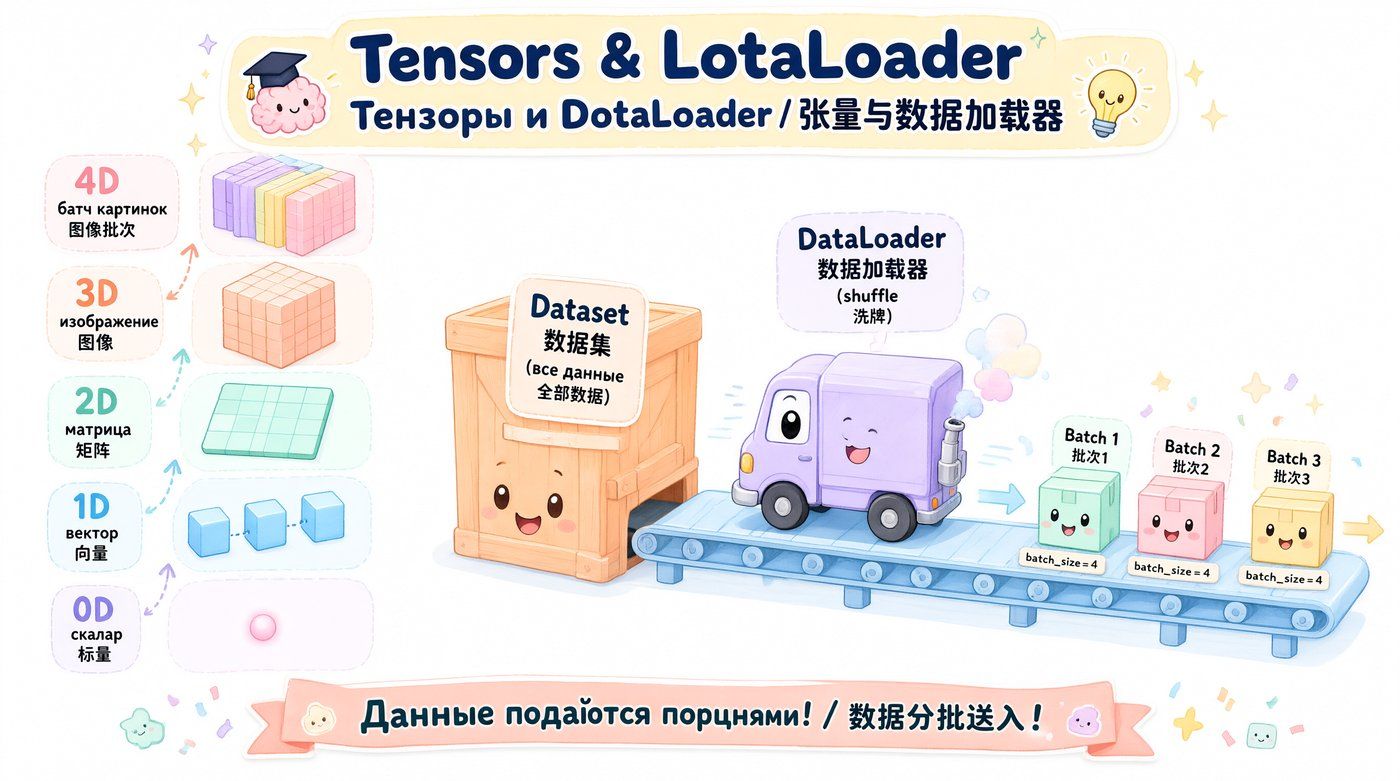
*Рис. 2. От скаляра до 4D-тензора. DataLoader берёт большой Dataset и выдаёт маленькие батчи.*

In [ ]:
# Демонстрация тензоров и DataLoader
import torch
from torch.utils.data import Dataset, DataLoader

# 1. Разные виды тензоров
scalar = torch.tensor(5)           # 0D
vector = torch.tensor([1, 2, 3])   # 1D
matrix = torch.tensor([[1, 2], [3, 4]])  # 2D

print(f"Скаляр (0D): {scalar.shape}")
print(f"Вектор (1D): {vector.shape}")
print(f"Матрица (2D): {matrix.shape}\n")

# 2. Простой Dataset: 20 примеров с 3 признаками
class SimpleDataset(Dataset):
    def __init__(self, n_samples=20):
        self.X = torch.randn(n_samples, 3)  # 20 строк, 3 признака
        self.y = torch.randint(0, 2, (n_samples,))  # метки 0 или 1

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# 3. DataLoader выдаёт данные батчами по 4 примера
dataset = SimpleDataset(n_samples=20)
dataloader = DataLoader(dataset, batch_size=4, shuffle=True)

print(f"📦 Всего примеров в Dataset: {len(dataset)}")
print(f"🚚 Размер батча: 4")
print(f"🔢 Количество батчей: {len(dataloader)} (20 / 4 = 5)\n")

# Получаем первый батч
for batch_idx, (X_batch, y_batch) in enumerate(dataloader):
    print(f"Батч №{batch_idx + 1}:")
    print(f"  Форма X (признаки): {X_batch.shape}  ← 4 примера по 3 признака")
    print(f"  Форма y (метки):    {y_batch.shape}  ← 4 метки")
    break  # посмотрим только первый

Скаляр (0D): torch.Size([])
Вектор (1D): torch.Size([3])
Матрица (2D): torch.Size([2, 2])

📦 Всего примеров в Dataset: 20
🚚 Размер батча: 4
🔢 Количество батчей: 5 (20 / 4 = 5)

Батч №1:
  Форма X (признаки): torch.Size([4, 3])  ← 4 примера по 3 признака
  Форма y (метки):    torch.Size([4])  ← 4 метки


## Цикл обучения: 5 шагов (45–70 мин)

В PyTorch обучение выглядит одинаково для любой модели — это **стандартный шаблон из 5 шагов**:

### 🔄 5 шагов одного шага обучения:
1. **`optimizer.zero_grad()`** — обнулить старые градиенты (иначе они накопятся).
2. **`predictions = model(X)`** — сделать прогноз (forward pass, «прямой проход»).
3. **`loss = criterion(predictions, y)`** — посчитать ошибку (функция потерь).
4. **`loss.backward()`** — вычислить градиенты (обратное распространение, «разбор полётов»).
5. **`optimizer.step()`** — сделать шаг: обновить веса в сторону уменьшения ошибки.

### 📖 Ключевые термины через аналогию с баскетболистом 🏀

| Термин | По-китайски | Аналогия с тренировкой баскетболиста |
|---|---|---|
| **Эпоха (Epoch)** | 轮次 | Один полный круг тренировки: игрок прошёл все упражнения. |
| **Батч (Batch)** | 批次 | Одна серия бросков (например, 32 броска подряд). |
| **Learning Rate** | 学习率 | Насколько сильно игрок меняет технику после каждой серии. |

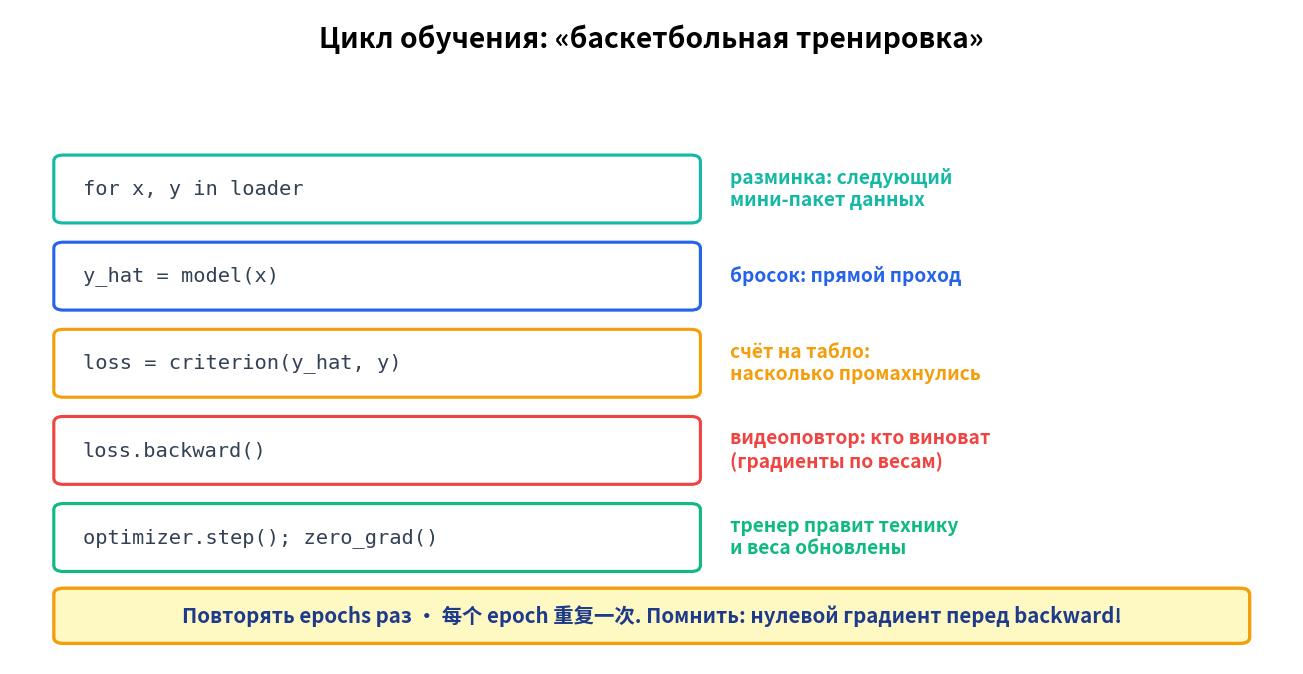

Эти пять строчек — скелет любого обучения, от игрушки до GPT. Прочувствуем их на живом примере:


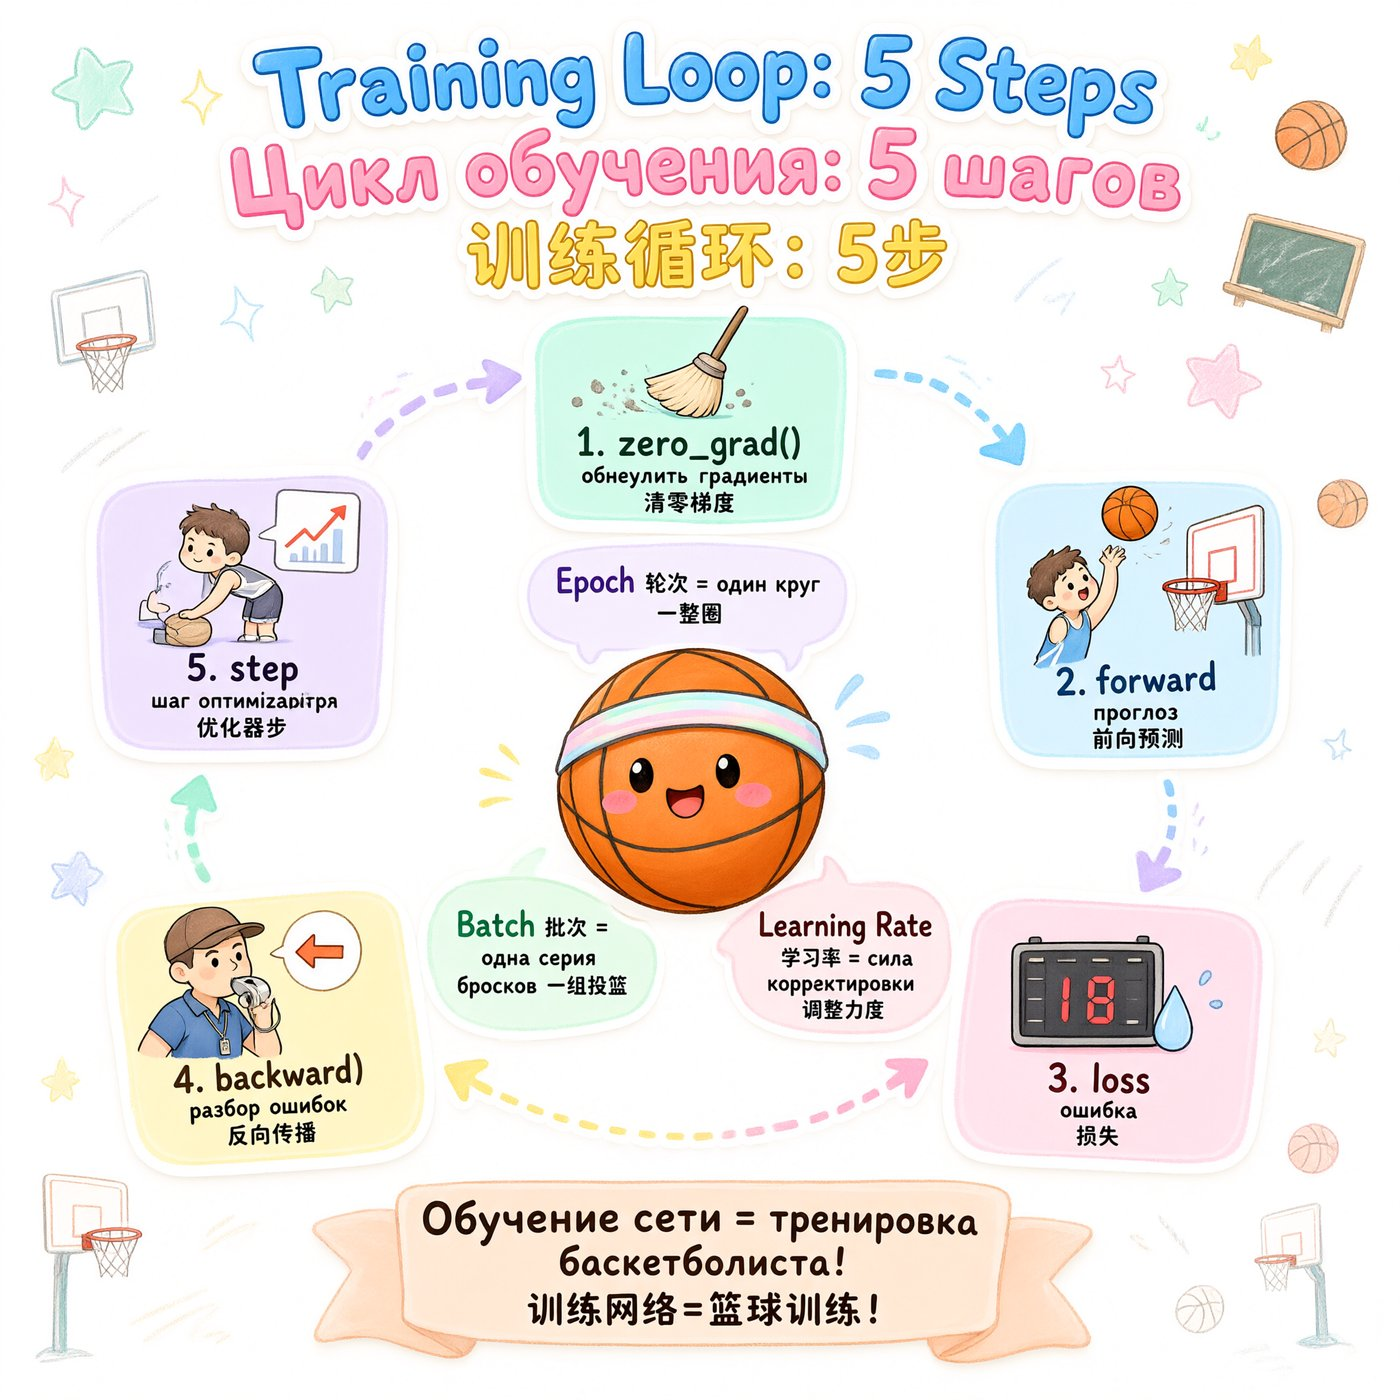

эпоха   0: потери 5.8221
эпоха 100: потери 0.0457
эпоха 200: потери 0.0003
эпоха 300: потери 0.0001
финальная MSE: 0.00006


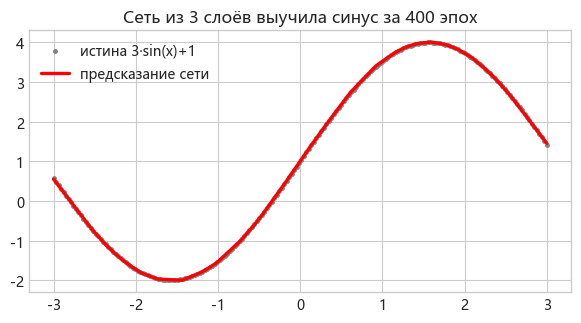

In [ ]:
# Мини-эксперимент: сеть учится «повторять» функцию y = sin(x)·3 + 1
torch.manual_seed(0)
X = torch.linspace(-3, 3, 200).reshape(-1, 1)
y_true = 3 * torch.sin(X) + 1

model = nn.Sequential(
    nn.Linear(1, 32), nn.ReLU(),
    nn.Linear(32, 32), nn.ReLU(),
    nn.Linear(32, 1),
)
opt = torch.optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.MSELoss()

for epoch in range(400):
    y_hat = model(X)                # 1) forward
    loss = loss_fn(y_hat, y_true)   # 2) loss
    opt.zero_grad()                 # (обнулить прошлые градиенты)
    loss.backward()                 # 3) backward
    opt.step()                      # 4) шаг оптимизатора
    if epoch % 100 == 0:
        print(f"эпоха {epoch:3d}: потери {loss.item():.4f}")

with torch.no_grad():
    pred = model(X)
print(f"финальная MSE: {loss.item():.5f}")

plt.figure(figsize=(7, 3.4))
plt.scatter(X, y_true, s=6, color='gray', label='истина 3·sin(x)+1')
plt.plot(X, pred, color='red', lw=2.4, label='предсказание сети')
plt.title('Сеть из 3 слоёв выучила синус за 400 эпох')
plt.legend(); plt.show()

In [ ]:
# Полный цикл обучения простой линейной модели на PyTorch
import torch
import torch.nn as nn
import torch.optim as optim

# Генерируем синтетические данные: y = 2*x1 + 3*x2 + шум
torch.manual_seed(42)
X = torch.randn(100, 2)
y = 2 * X[:, 0] + 3 * X[:, 1] + torch.randn(100) * 0.1  # истинные веса: 2 и 3

# 1. Создаём простую модель (один линейный слой)
model = nn.Linear(in_features=2, out_features=1)

# 2. Функция потерь (MSE для регрессии)
criterion = nn.MSELoss()

# 3. Оптимизатор (SGD с learning rate = 0.01)
optimizer = optim.SGD(model.parameters(), lr=0.01)

# Цикл обучения: 50 эпох
print("🏀 Начинаем тренировку!\n")
for epoch in range(500):
    # === 5 ШАГОВ ОБУЧЕНИЯ ===
    optimizer.zero_grad()        # 1. Обнулить градиенты
    predictions = model(X)       # 2. Сделать прогноз
    loss = criterion(predictions.squeeze(), y)  # 3. Посчитать потери
    loss.backward()              # 4. Вычислить градиенты (backward)
    optimizer.step()             # 5. Обновить веса

    if (epoch + 1) % 10 == 0:
        print(f"Эпоха {epoch+1:2d}: Loss = {loss.item():.4f}")

# Смотрим, какие веса выучила модель (должны быть близки к 2 и 3)
weights = model.weight.detach().numpy().flatten()
bias = model.bias.detach().numpy()[0]
print(f"\n✅ Выученные веса: {weights[0]:.3f}, {weights[1]:.3f} (истина: 2, 3)")
print(f"📌 Смещение (bias): {bias:.3f}")

🏀 Начинаем тренировку!

Эпоха 10: Loss = 13.0319
Эпоха 20: Loss = 8.7348
Эпоха 30: Loss = 5.8851
Эпоха 40: Loss = 3.9883
Эпоха 50: Loss = 2.7204
Эпоха 60: Loss = 1.8689
Эпоха 70: Loss = 1.2940
Эпоха 80: Loss = 0.9036
Эпоха 90: Loss = 0.6367
Эпоха 100: Loss = 0.4529
Эпоха 110: Loss = 0.3255
Эпоха 120: Loss = 0.2365
Эпоха 130: Loss = 0.1738
Эпоха 140: Loss = 0.1292
Эпоха 150: Loss = 0.0972
Эпоха 160: Loss = 0.0742
Эпоха 170: Loss = 0.0574
Эпоха 180: Loss = 0.0451
Эпоха 190: Loss = 0.0360
Эпоха 200: Loss = 0.0292
Эпоха 210: Loss = 0.0242
Эпоха 220: Loss = 0.0204
Эпоха 230: Loss = 0.0175
Эпоха 240: Loss = 0.0153
Эпоха 250: Loss = 0.0137
Эпоха 260: Loss = 0.0124
Эпоха 270: Loss = 0.0114
Эпоха 280: Loss = 0.0107
Эпоха 290: Loss = 0.0101
Эпоха 300: Loss = 0.0097
Эпоха 310: Loss = 0.0093
Эпоха 320: Loss = 0.0090
Эпоха 330: Loss = 0.0088
Эпоха 340: Loss = 0.0087
Эпоха 350: Loss = 0.0086
Эпоха 360: Loss = 0.0085
Эпоха 370: Loss = 0.0084
Эпоха 380: Loss = 0.0083
Эпоха 390: Loss = 0.0083
Эпоха 400

---
## 🎬 Все видеоматериалы лекции 5
### 🇷🇺 РУС · русскоязычные видео (21)
| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [2. [RUS ИИ Перевод] Neurons and the brain — Нейроны и мозг](https://vkvideo.ru/video-227991006_456239265) | VK · Нга-НС | 10:51 | Л5 §1: искусственный нейрон — от биологии к арифметике · [добавлено] | X |
| 2 | [3. [RUS ИИ Перевод] Demand Prediction — Прогнозирование спроса](https://vkvideo.ru/video-227991006_456239266) | VK · Нга-НС | 16:23 | Л5 §1: нейрон как модель, делающая предсказание · [добавлено] | X |
| 3 | [5. [RUS ИИ Перевод] Neural network layer — Слои нейросети и их порядок](https://vkvideo.ru/video-227991006_456239268) | VK · Нга-НС | 9:49 | Л5 §3: слои нейросети и их порядок · [добавлено] | X |
| 4 | [22. [RUS ИИ Перевод] Why do we need activation functions — Зачем вообще нужны функции активации](https://vkvideo.ru/video-227991006_456239328) | VK · Нга-НС | 5:29 | Л5 §2: зачем вообще нужны функции активации · [добавлено] | X |
| 5 | [30. [RUS ИИ Перевод] What is a derivative? (Optional) — Что такое производная? (опционально)](https://vkvideo.ru/video-227991006_456239336) | VK · Нга-НС | 22:56 | П5 Часть Б: производные и градиенты (основа autograd) · [добавлено] | X |
| 6 | [[3Blue1Brown RU] DeepLearning Ч.1. Что же такое нейронная сеть?](https://rutube.ru/video/9da8798d121947a2ce2a9fc2fe657ea8)<br>· ориг.: *But what is a neural network? (озвучка Alex_Nik)* | Rutube · Alex_Nik | 19 мин | Л5 §1–3: альтернативная озвучка серии | X |
| 7 | [[3Blue1Brown RU] DeepLearning Ч.2. Градиентный спуск: как учатся сети](https://rutube.ru/video/ac51e93eacb8179e8d9c258dc76ecf26)<br>· ориг.: *Gradient descent (озвучка Alex_Nik)* | Rutube · Alex_Nik | 20 мин | Л5 §4: спуск по функции потерь | X |
| 8 | [[3Blue1Brown RU] DeepLearning Ч.3. Суть метода обратного распространения](https://rutube.ru/video/1efa62f4d186e910d1d44d69949cbfa2)<br>· ориг.: *What is backpropagation really doing? (озвучка Alex_Nik)* | Rutube · Alex_Nik | 13 мин | Л5 §4.3: backprop на интуиции | X |
| 9 | [[3Blue1Brown RU] DeepLearning Ч.4. Формулы обратного распространения](https://rutube.ru/video/030335d8cc5c90fdc4e4652d7926e88d)<br>· ориг.: *Backpropagation calculus (озвучка Alex_Nik)* | Rutube · Alex_Nik | 10 мин | Л5 §4.3: цепное правило математически | X |
| 10 | [[3Blue1Brown] Матанализ, Гл.1. Суть матанализа](https://rutube.ru/video/60ae41c0c62470972eb9e52a4d216835) | Rutube · Alex_Nik | 16 мин | Л5 §4: производная = наклон — база градиентного спуска | X |
| 11 | [Нейросети: #1. Глубокое обучение I [3Blue1Brown]](https://vkvideo.ru/video-55155418_456242620)<br>· ориг.: *But what is a neural network?* | Vert Dider (VK/Rutube) | 18 мин | Л5 §1–3: нейроны, слои, веса и смещения (на примере MNIST) | X |
| 12 | [Нейросети: #2. Глубокое обучение II: градиентный спуск](https://vkvideo.ru/video-55155418_456242659)<br>· ориг.: *Gradient descent, how neural networks learn* | Vert Dider (VK/Rutube) | 20 мин | Л5 §4: функция потерь и градиент | X |
| 13 | [Введение в нейронные сети. Часть 1. История развития Deep Learning](https://vkvideo.ru/video-155161349_456239204) | VK · DLS-1 | 23:43 | Л5: контекст — история развития глубокого обучения · [добавлено] | X |
| 14 | [Введение в нейронные сети. Часть 2. Механизм обратного распространения ошибки](https://vkvideo.ru/video-155161349_456239205) | VK · DLS-1 | 26:18 | Л5: механизм обратного распространения ошибки · [добавлено] | X |
| 15 | [Введение в нейронные сети. Часть 3. Функции активации. Краткий обзор применений CNN и RNN](https://vkvideo.ru/video-155161349_456239207) | VK · DLS-1 | 21:37 | Л5 §2: функции активации, ReLU · [добавлено] | X |
| 16 | [ML #45. Нейронные сети. Краткое введение в теорию](https://rutube.ru/video/02c52f69f873efab31bfec37f4a0ee91) | Rutube · SelfEdu | 15 мин | Л5 §1: теория до перехода на PyTorch | X |
| 17 | [ML #46. Обучение нейронной сети. Back propagation](https://rutube.ru/video/e613e5e6eae1dab9ada15206dbe9de96) | Rutube · SelfEdu | 15 мин | Л5 §4.3: backprop без фреймворка | X |
| 18 | [Py #1. Структура и принцип работы полносвязных нейронных сетей](https://rutube.ru/video/172d535a72860ec34bacb8afa1610c49) | Rutube · SelfEdu | 11 мин | Л5 §1–3: полносвязная архитектура | X |
| 19 | [Py #11. Идея обучения НС градиентным алгоритмом](https://rutube.ru/video/4c1f65ab0dc85104034a8fa8a7924983) | Rutube · SelfEdu | 12 мин | Л5 §4: обучение как поиск минимума | X |
| 20 | [Py #12. Алгоритм back propagation. Пример работы](https://rutube.ru/video/520d1a16d3eb0ee0790e55fee5548625) | Rutube · SelfEdu | 13 мин | Л5 §4.3: обратное распространение ошибки | X |
| 21 | [Py #13. Функции активации и потерь в PyTorch](https://rutube.ru/video/adb67ef6371fb898fbf49ced01d808b7) | Rutube · SelfEdu | 10 мин | Л5 §2: активации; выбор функции потерь | X |

### 🇨🇳 中文 · китайскоязычные видео (10)
| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [От функции к нейронной сети](https://www.bilibili.com/video/BV1DgxCzREbM?p=1)<br>· ориг.: *【入门篇】从函数到神经网络* | Bilibili (анимакурс) | 9 мин | Л5 §1: от биологии нейрона к арифметике | ✓ |
| 2 | [Перцептрон](https://www.bilibili.com/video/BV1EY6FBwE8P?p=32)<br>· ориг.: *32.1-感知机-* | Bilibili · 李沐 | 13 мин | Л5 §1: история — перцептрон Розенблатта | ✓ |
| 3 | [Инициализация модели и функции активации](https://www.bilibili.com/video/BV1EY6FBwE8P?p=48)<br>· ориг.: *48.2-模型初始化和激活函数* | Bilibili · 李沐 | 24 мин | Л5 §2: нелинейности и численная стабильность | ✓ |
| 4 | [Многослойный перцептрон](https://www.bilibili.com/video/BV1EY6FBwE8P?p=33)<br>· ориг.: *33.2-多层感知机* | Bilibili · 李沐 | 22 мин | Л5 §3: слои и глубина | ✓ |
| 5 | [Многослойный перцептрон (MLP)](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=36)<br>· ориг.: *7-1 多层感知器(MLP)* | Bilibili · 清华AI | 18 мин | Л5 §3: от одного нейрона к сети | ✓ |
| 6 | [Многослойный перцептрон: код](https://www.bilibili.com/video/BV1EY6FBwE8P?p=34)<br>· ориг.: *34.3-代码实现-* | Bilibili · 李沐 | 8 мин | Л5 §3: MLP в PyTorch | ✓ |
| 7 | [Градиент (математический минимум)](https://www.bilibili.com/video/BV1BYe4z5E9z?p=8)<br>· ориг.: *008_数学基础_梯度* | Bilibili · 尚硅谷 | 10 мин | Л5 §4: что такое градиент | ✓ |
| 8 | [Обратное распространение ошибки](https://www.bilibili.com/video/BV1Y7411d7Ys?p=4)<br>· ориг.: *04.反向传播* | Bilibili · 刘二大人 | 46 мин | Л5 §4.3: backpropagation | ✓ |
| 9 | [Как обучать нейросеть](https://www.bilibili.com/video/BV1DgxCzREbM?p=3)<br>· ориг.: *【入门篇】调教神经网络的方法* | Bilibili (анимакурс) | 7 мин | Л5 §4: потери, градиент, обратная волна | ✓ |
| 10 | [Метод Dropout](https://www.bilibili.com/video/BV1EY6FBwE8P?p=44)<br>· ориг.: *44.1-丢弃法* | Bilibili · 李沐 | 12 мин | Л5 §5 / П6: борь



### 🇬🇧 EN · англоязычные видео (9)
| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [Andrew Ng: Нейроны и мозг](https://www.bilibili.com/video/BV1owrpYKEtP?p=39)<br>· ориг.: *39.神经元与大脑 (речь — английская)* | Bilibili · 吴恩达 | 10 мин | Л5 §1: биологическое вдохновение | ✓ |
| 2 | [StatQuest: основные идеи нейросетей (с нуля)](https://www.bilibili.com/video/BV18m411S79t)<br>· ориг.: *【官方双语】神经网络基本思想，从零开始理解深度学习！* | Bilibili · StatQuest | 18 мин | Л5 §1–3: нейрон → слои → выход | ✓ |
| 3 | [StatQuest: функция активации ReLU на примере](https://www.bilibili.com/video/BV15x4y1U7T3)<br>· ориг.: *【官方双语】一个例子彻底理解ReLU激活函数* | Bilibili · StatQuest | 9 мин | Л5 §2: активации (ReLU) | ✓ |
| 4 | [Andrew Ng: Слои нейронной сети](https://www.bilibili.com/video/BV1owrpYKEtP?p=42)<br>· ориг.: *42.神经网络层 (речь — английская)* | Bilibili · 吴恩达 | 9 мин | Л5 §3: слои и forward propagation | ✓ |
| 5 | [StatQuest: многомерные входы и выходы нейросети](https://www.bilibili.com/video/BV1oZ421t7SY)<br>· ориг.: *【官方双语】逐步解析神经网络的多元输入与输出 ！！！* | Bilibili · StatQuest | 13 мин | Л5 §3: слои и матрицы | ✓ |
| 6 | [StatQuest: градиентный спуск шаг за шагом](https://www.bilibili.com/video/BV1XW421F7M4)<br>· ориг.: *【官方双语】零基础梯度下降法，手把手教你优化损失函数！* | Bilibili · StatQuest | 23 мин | Л5 §4: как сеть учится — оптимизация | ✓ |
| 7 | [StatQuest: как кросс-энтропия участвует в backprop](https://www.bilibili.com/video/BV1QJ4m1G7jt)<br>· ориг.: *【官方双语】交叉熵损失函数怎么进行反向传播来优化神经网络参数？* | Bilibili · StatQuest | 22 мин | Л5 §4: потеря + backprop | ✓ |
| 8 | [StatQuest: строим нейросеть на PyTorch](https://www.bilibili.com/video/BV1um41127Fo)<br>· ориг.: *【官方双语】一步一步带你用PyTorch构建神经网络！* | Bilibili · StatQuest | 23 мин | Л5: PyTorch на практике | ✓ |
| 9 | [吴恩达《深度学习》（полная специализация)](https://www.bilibili.com/video/BV12urfB1E7s) | Bilibili · 吴恩达 DL | курс · 192 эп., 893 тыс. просм. | Л5+: глубокое обучение целиком ·  | ✓ |



## Мини-тест и итоги (85–90 мин)

### ❓ Вопросы для самопроверки

1. **Чем эпоха (epoch) отличается от батча (batch)?**  
    <details>*(Ответ: Эпоха — один полный проход по ВСЕМ данным. Батч — одна порция данных, обрабатываемая за один раз. В одной эпохе может быть много батчей.)* </details>

2. **Что будет, если скорость обучения (learning rate) слишком большая?**  
    <details>*(Ответ: Модель будет «перепрыгивать» через минимум функции потерь, ошибка может расти, а обучение — расходиться (не сойдётся).)* </details>

3. **Назовите два способа борьбы с переобучением.**  
    <details>*(Ответ: любые два из: больше данных, аугментация, dropout, ранняя остановка, упрощение модели.)* </details>


### Контрольные вопросы

Нажмите на вопрос, чтобы раскрыть образец ответа.

**1. Проследите шаги градиентного спуска для L = w² из точки w = 2 при скорости обучения 0,2. Что произойдёт при 1,1 и почему?**
<details>
<summary>Показать ответ</summary>
При η = 0,2 шаг w ← w − 0,4w: <b>2 → 1,2 → 0,72 → 0,43 → 0,26 → …</b> — вес плавно катится к минимуму. При η = 1,1: <b>2 → −2,4 → 2,88 → −3,46 → …</b> — шаг перепрыгивает дно долины, раскачка нарастает, обучение <b>расходится</b>. Мораль: скорость обучения начинают с консервативных 0,001–0,01.
</details>

**2. Объясните своими словами, почему обучение сети — это поиск минимума функции потерь, а не «запоминание ответов».**
<details>
<summary>Показать ответ</summary>
Сеть не хранит примеры: она <b>подбирает веса</b>, при которых ошибка (функция потерь) минимальна сразу на всех примерах. Найденное правило-закономерность работает и на данных, которых сеть не видела. Зубрёжка — это переобучение: ноль ошибки на train и провал на тесте.
</details>

**3. Что делает обратное распространение ошибки и почему без него невозможно обучать сети с миллионами весов?**
<details>
<summary>Показать ответ</summary>
Backprop идёт от ошибки на выходе <b>назад по слоям</b> и по цепному правилу вычисляет вклад каждого веса в общую ошибку. Один проход по сети даёт точное направление и величину шага для <b>всех миллионов весов сразу</b>; без него пришлось бы перебирать веса по одному — это вечность.
</details>

**4. Почему один нейрон с сигмоидой — это в точности логистическая регрессия из лекции 4?**
<details>
<summary>Показать ответ</summary>
Формулы совпадают буква в букву: логистическая регрессия — σ(w₁x₁ + … + b), один нейрон — взвешенная сумма + та же сигмоида как активация. «Нейрон» и «логистическая регрессия» — это одна и та же математика, отличается только название.
</details>

**5. Зачем сети скрытые слои? Почему задачу XOR не решает один нейрон?**
<details>
<summary>Показать ответ</summary>
Один нейрон — одна прямая (линейная граница), а точки XOR («класс 1, если входы разные») <b>никакой прямой не разделяются</b>. Скрытый слой «перепаковывает» пространство: в новых координатах классы уже ложатся по разные стороны прямой. Каждый следующий слой выгибает пространство сильнее — в этом магия глубины.
</details>

**6. Зачем b, если можно добавить вход, всегда равный 1?**
<details>
<summary>Показать ответ</summary>
Математически <b>эквивалентно</b>: смещение — это просто вес входа, всегда равного 1. Отличная запись для формул и реализации; вопрос-капкан на собеседованиях проверяет, понимаете ли вы, что b — такой же обучаемый вес, как остальные.
</details>

**7. Что случится с обучением при learning rate 1e-7? А при 10?**
<details>
<summary>Показать ответ</summary>
При 1e-7 шаги микроскопические: потери почти не падают, обучение займёт «вечность» (ползем вместо шага). При 10 шаги перепрыгивают минимум, потери растут — обучение расходится. Рабочий старт: 0,001 для Adam, 0,01 для SGD, затем уменьшать по расписанию.
</details>

**8. Объясните backprop человеку, который знает только цепное правило из школы.**
<details>
<summary>Показать ответ</summary>
Это «разбор полётов» задом наперёд: сначала считаем промах на выходе, потом идём назад по цепочке и на каждом звене спрашиваем «насколько ты виноват в ошибке?» — вклады перемножаются вдоль цепочки (та же производная сложной функции). Дойдя до первого слоя, знаем поправку для каждого веса.
</details>

**9. Кривая train падает, test растёт с эпохи 15. Ваши три действия?**
<details>
<summary>Показать ответ</summary>
Это переобучение, начавшееся с эпохи 15. Действия: <b>1.</b> вернуться к модели эпохи 15 (ранняя остановка); <b>2.</b> добавить данных или аугментацию; <b>3.</b> включить Dropout/L2-регуляризацию или упростить сеть.
</details>

**10. Почему мини-пакет из одного примера — плохая идея, и из миллиона — тоже?**
<details>
<summary>Показать ответ</summary>
Из одного примера: градиент каждого шага считается по одному объекту — слишком шумно, шаги хаотичны, GPU простаивает. Из миллиона: не влезает в память, один шаг — вечность, а шумовой «пользы» от этого нет. Баланс — 32–256 примеров: шум даже полезен, он выпрыгивает из ям-обманок.
</details>

**11. Чем Adam отличается от «чистого» SGD одной фразой?**
<details>
<summary>Показать ответ</summary>
Adam подбирает <b>индивидуальный шаг для каждого веса</b> (адаптивные моменты), тогда как у «чистого» SGD шаг один и тот же для всех весов.
</details>


## 📚 Глоссарий Лекции 5 (词汇表)

Термины нейросетей и PyTorch (термины CNN — в Лекции 6).

| Термин (рус) | English | 中文 | Пояснение |
|--------------|---------|------|-----------|
| Нейрон | Neuron | 神经元 | Вычисляет взвешенную сумму + активацию; базовая единица сети. |
| Вес | Weight | 权重 | Параметр нейрона, который учится; умножается на вход. |
| Смещение | Bias | 偏置 | Аддитивный параметр нейрона; сдвигает активацию. |
| Активация | Activation function | 激活函数 | Нелинейность (ReLU, sigmoid); без неё сеть любой глубины линейна. |
| ReLU | Rectified Linear Unit | 修正线性单元 | f(x) = max(0, x); стандарт скрытых слоёв современной сети. |
| Сигмоида | Sigmoid | 逻辑斯蒂函数 | f(x) = 1/(1+e^−x); выход в (0,1); для бинарной классификации. |
| Скрытый слой | Hidden layer | 隐藏层 | Промежуточный слой; даёт сети «глубину» и перепаковку признаков. |
| Функция потерь | Loss function | 损失函数 | Мера ошибки модели (MSE, CrossEntropy); её минимизирует обучение. |
| Градиент | Gradient | 梯度 | Вектор частных производных; направление роста потерь. |
| Градиентный спуск | Gradient descent | 梯度下降 | Шаг весов в сторону антиградиента; минимизация потерь. |
| Backpropagation | Backpropagation | 反向传播 | Эффективный расчёт градиентов по всем весам через цепное правило. |
| Learning rate | Learning rate | 学习率 | Шаг обновления весов; главный гиперпараметр. |
| Эпоха | Epoch | 轮次 | Один полный проход по обучающим данным. |
| Батч | Batch | 批次 | Порция данных для одного шага градиента; обычно 32, 64, 128. |
| Переобучение | Overfitting | 过拟合 | Сеть выучила шум; лечится данными, dropout, L2, ранней остановкой. |
| Dropout | Dropout | 丢弃法 | Случайное обнуление части нейронов при обучении; регуляризация. |
| Ранняя остановка | Early stopping | 早停 | Прекращение обучения, когда val_loss начинает расти. |
| PyTorch | PyTorch | PyTorch | Библиотека глубокого обучения от Meta; тензоры + autograd. |
| Autograd | Autograd | 自动微分 | Автоматическое вычисление градиентов через граф вычислений. |
| PaddlePaddle | PaddlePaddle | 飞桨 | Китайский DL-фреймворк от Baidu; альтернатива PyTorch. |


## 🎓 Итоги Лекции 5

Лекция провела путь от биологического нейрона к полному циклу обучения сети: вес и смещение, нелинейная активация (ReLU), скрытые слои и XOR, функция потерь, градиентный спуск, backprop, переобучение и регуляризация, минимальный цикл PyTorch.

### 🔑 Главные выводы

1. Нейрон = взвешенная сумма + смещение + нелинейность: $\hat{y} = f(\mathbf{w}\mathbf{x} + b)$.
2. Без нелинейных активаций сеть любой глубины — линейная карта. ReLU — стандарт скрытых слоёв.
3. Скрытые слои перепаковывают пространство признаков (XOR!) — глубина строит иерархии признаков.
4. Обучение = минимизация потерь градиентным спуском; backprop доставляет градиент каждому весу цепным правилом; learning rate — главный гиперпараметр.
5. Переобучение видно по расхождению кривых train/test; лечится данными, L2, dropout, ранней остановкой.
6. PyTorch = тензоры + автоград + слои + потери + оптимизатор; цикл `forward → loss → backward → step`. PaddlePaddle и MindSpore — те же идеи, другой синтаксис.

### 📝 Домашнее задание

1. **Руками и кодом.** Нейрон из вопроса 1 — посчитайте в тетради, затем проверьте в NumPy. Смените активацию на сигмоиду — что изменится?
2. **XOR на практике.** Обучите маленькую сеть (2→4→1, ReLU) на XOR в PyTorch (2000 эпох, lr=0.05). Достигните ошибки < 0.05. Нарисуйте предсказания поверх точек.
3. **Эксперимент с шагом.** В примере с синусом проставьте lr = 1.0, затем 0.001. Опишите разницу в 2–3 предложениях: сколько эпох нужно, что с потерями?

### 📅 Следующее занятие

**Лекция 6: Глубокое обучение и свёрточные нейронные сети**

**Практика 5: Первая нейросеть и основы PyTorch**

---

<center><i>Преподаватель: _______________</i></center>
<center><i>Дата проведения: _______________</i></center>